# Validating the research record before estimation

The family tested in the backtest must be exactly the family corrected for multiple testing:

$$
\mathcal F_6=\mathcal F_7=\{\mathrm{A},\mathrm{B},\mathrm{C}\}.
$$

Here, $\mathcal F_6$ is the family declared before the Stage 6 backtest; $\mathcal F_7$ is the family supplied to the Stage 7 correction; and A, B, and C are the three declared strategy trials.

,Stage,Family,Declared trials,Trial count
0,Stage 6 backtest,declared-family,"Strategy A, Strategy B, Strategy C",3
1,Stage 7 adjustment,declared-family,"Strategy A, Strategy B, Strategy C",3


,Partition,Trials,Trial count
0,Primary,"Strategy A, Strategy B",2
1,Robustness,Strategy C,1


,Partition,Strategy A,Strategy B,Strategy C
0,Primary,1,1,0
1,Robustness,0,0,1


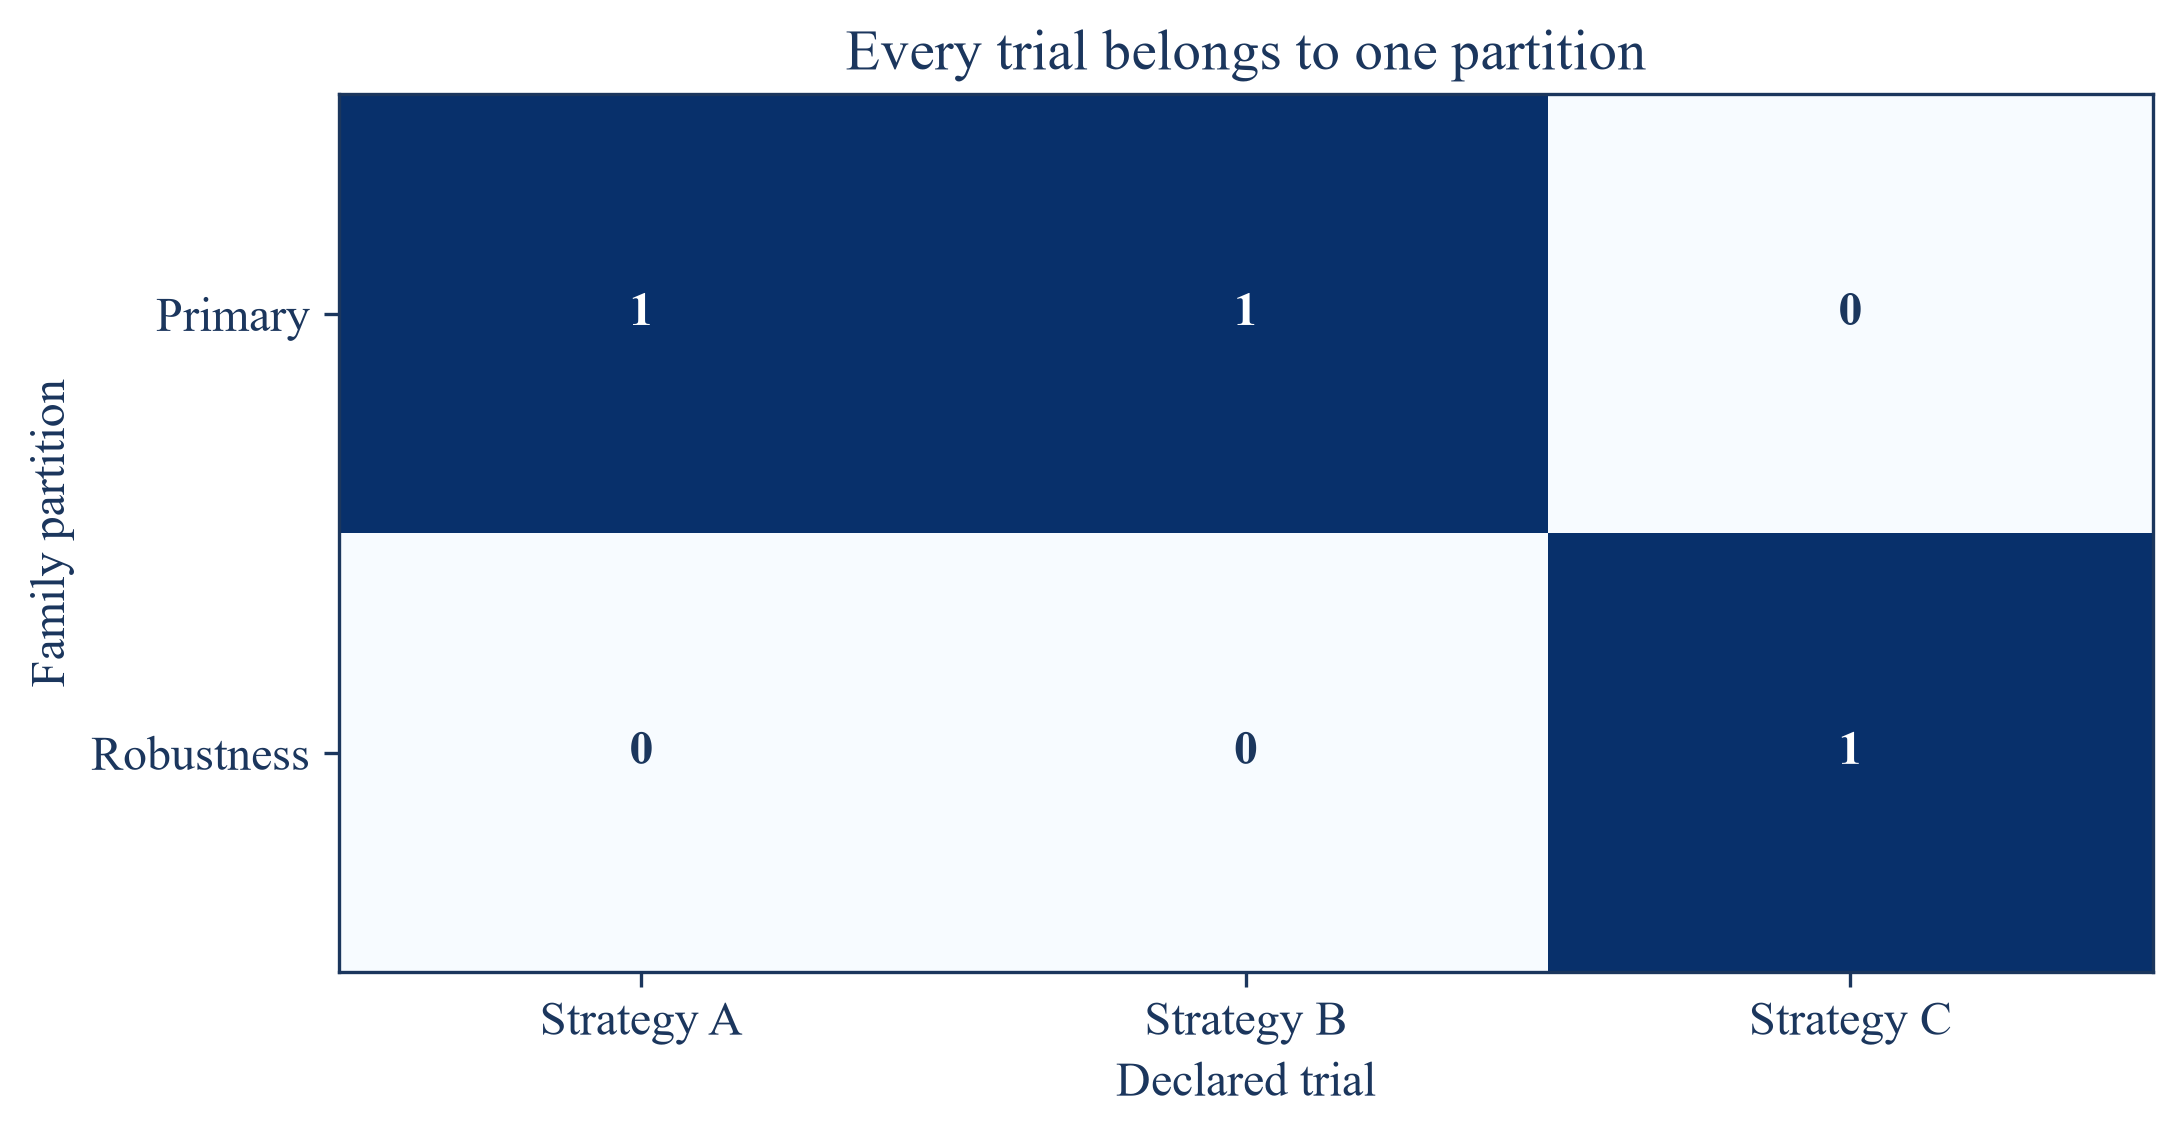

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from dataclasses import FrozenInstanceError, fields, replace
import inspect
import math
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd
from scipy.stats import norm, t as student_t
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.causal_factor_analysis.protocol import BacktestStage, CausalAdjustmentSetStage, CausalDiscoveryStage, CausalExplanatoryAndPredictivePowerStage, CausalFactorProtocolReport, CausalPortfolioConstructionStage, EventHorizon, FoldEvidence, MultipleTestingAdjustmentsStage, ValidationEvidence, VariableSelectionStage, validate_causal_factor_protocol

FIGURES = ROOT / "outputs" / "figures" / "10_causal_factor_protocol"
TABLES = ROOT / "outputs" / "tables" / "10_causal_factor_protocol"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def human_label(value):
    special = {"PC": "PC", "LINGAM": "LiNGAM", "R_SQUARED": "R squared", "MEAN_SQUARED_ERROR": "Mean squared error", "BENJAMINI_HOCHBERG": "Benjamini-Hochberg", "DEFLATED_SHARPE_RATIO": "Deflated Sharpe ratio"}
    return special.get(value, value.replace("_", " ").title())

def contract_case(name, stage, action):
    try:
        action()
        return {"Case": name, "Stage": stage, "Result": "Accepted", "Message": "Record satisfies the released checks", "Rejected": False}
    except Exception as error:
        message = str(error).replace("Causal factor protocol is invalid. ", "")
        message = message.split(". ", 1)[0].rstrip(".")
        return {"Case": name, "Stage": stage, "Result": "Rejected", "Message": message, "Rejected": True}

public_dates = industry_returns.index[:6]
observation_ids = tuple(f"event-{date:%Y-%m-%d}" for date in public_dates)

def make_horizons():
    intervals = ((0.0, 2.0), (1.0, 3.0), (4.0, 5.0), (6.0, 7.0), (8.0, 9.0), (10.0, 11.0))
    return tuple(EventHorizon(observation_id, start, end) for observation_id, (start, end) in zip(observation_ids, intervals))

def make_fold(fold_id, path_id, train_positions, test_positions, refit_id):
    train_ids = tuple(observation_ids[index] for index in train_positions)
    test_ids = tuple(observation_ids[index] for index in test_positions)
    return FoldEvidence(fold_id=fold_id, path_id=path_id, train_ids=train_ids, test_ids=test_ids, fit_ids=train_ids, prediction_ids=test_ids, refit_id=refit_id, refit_components=("VARIABLE_SELECTION", "CAUSAL_ESTIMATION", "PORTFOLIO_CONSTRUCTION"))

def temporal_validation(method_labels=("PURGED_CROSS_VALIDATION",), embargo=1.0):
    return ValidationEvidence(method_labels=method_labels, event_horizons=make_horizons(), folds=(make_fold("f1", "p1", (2, 3, 4, 5), (0, 1), "r1"), make_fold("f2", "p1", (0, 1, 4, 5), (2, 3), "r2"), make_fold("f3", "p1", (0, 1, 2, 3), (4, 5), "r3")), embargo=embargo)

def cpcv_validation():
    return ValidationEvidence(method_labels=("COMBINATORIAL_PURGED_CROSS_VALIDATION",), event_horizons=make_horizons(), folds=(make_fold("p1-f1", "p1", (2, 3, 4, 5), (0, 1), "p1-r1"), make_fold("p1-f2", "p1", (0, 1, 4, 5), (2, 3), "p1-r2"), make_fold("p1-f3", "p1", (0, 1, 2, 3), (4, 5), "p1-r3"), make_fold("p2-f1", "p2", (3, 4, 5), (0, 2), "p2-r1"), make_fold("p2-f2", "p2", (2, 3, 5), (1, 4), "p2-r2"), make_fold("p2-f3", "p2", (0, 1, 2), (3, 5), "p2-r3")), embargo=1.0)

def valid_protocol_report():
    trial_ids = ("strategy-a", "strategy-b", "strategy-c")
    family_id = "declared-family"
    selection_validation = temporal_validation()
    evaluation_validation = temporal_validation()
    return CausalFactorProtocolReport(trial_family_id=family_id, declared_trial_ids=trial_ids, variable_selection=VariableSelectionStage(purpose="RISK_PREMIA_HARVESTING", selected_variables=("X", "Z", "I", "M", "C", "D"), method_labels=("MUTUAL_INFORMATION", "SHAPLEY_VALUES", "MEAN_DECREASE_IMPURITY", "PERMUTATION_FEATURE_IMPORTANCE"), overlapping_returns=True, strong_time_dependence=True, validation=selection_validation), causal_discovery=CausalDiscoveryStage(method_labels=("PC", "ECONOMIC_REASONING", "DOMAIN_EXPERTISE", "OBSERVED_OUTCOMES"), graph_id="resolved-dag", graph_nodes=("X", "Y", "Z", "I", "M", "C", "D"), directed_edges=(("Z", "X"), ("Z", "Y"), ("I", "X"), ("X", "M"), ("M", "Y"), ("X", "Y"), ("X", "C"), ("Y", "C"), ("X", "D")), graph_kind="DAG", ambiguous_edges=(), assumptions=("The recorded variables are sufficient for the target effect.", "Directions use time order and economic restrictions.")), causal_adjustment_set=CausalAdjustmentSetStage(treatment="X", outcome="Y", method_label="BACKDOOR_ADJUSTMENT", identified=True, admissible_adjustment_sets=(("Z",),), selected_adjustment_set=("Z",), confounders=("Z",), descendants=("M", "C", "D"), mediators=("M",), colliders=("C",), instruments=("I",), control_justifications=(("Z", "Common cause of factor and return."),), open_backdoor_paths=()), causal_explanatory_and_predictive_power=CausalExplanatoryAndPredictivePowerStage(task_types=("RETURN_SIZE",), estimator_label="fold-refit causal regression", explanatory_metric_labels=("R_SQUARED",), predictive_metric_labels=("MEAN_SQUARED_ERROR", "SPEARMAN_CORRELATION"), explanatory_evidence_id="explanatory-evidence", predictive_evidence_id="predictive-evidence", naive_benchmark_id="training-mean-benchmark", validation=evaluation_validation), causal_portfolio_construction=CausalPortfolioConstructionStage(method_labels=("POSITION_SIZING", "EXPOSURE_CONTROL", "ECONOMIC_RATIONALE", "FRAGILITY_STRESS_TEST", "TRANSACTION_COST_OPTIMIZATION", "TRANSFER_COEFFICIENT"), causal_exposures=("X",), controlled_unintended_exposures=("C", "D"), cost_model_id="cost-record", constraint_set_id="constraint-record", economic_rationale="Positions target the supplied X to Y effect.", fragility_scenarios=("weaken X to Y", "perturb Z to X"), transfer_coefficient=0.82), backtest=BacktestStage(method_labels=("COMBINATORIAL_PURGED_CROSS_VALIDATION",), trial_family_id=family_id, declared_trial_ids=trial_ids, validation=cpcv_validation()), multiple_testing_adjustments=MultipleTestingAdjustmentsStage(method_labels=("HOLM", "DEFLATED_SHARPE_RATIO"), trial_family_id=family_id, declared_trial_ids=trial_ids, family_partitions=(("primary", ("strategy-a", "strategy-b")), ("robustness", ("strategy-c",))), alpha=0.05, backtests_independent=False, p_value_estimator="estimator accounting for time dependence", time_dependence_model="purged temporal folds", p_value_inputs_assume_independence=False, sharpe_variance=0.04, effective_trials=2.0, sample_length=252, skewness=0.1, kurtosis=3.2, selection_bias_evidence_id="selection-bias-evidence"))

def public_trial_returns():
    base = industry_returns.iloc[:, :12].mean(axis=1).rename("Market basket")
    direction = np.sign(base.shift(1)).replace(0.0, 1.0)
    trials = pd.DataFrame({"Strategy A": base, "Strategy B": direction * base, "Strategy C": -direction * base})
    return trials.loc["2023-01-01":"2025-12-31"].dropna()

def draw_causal_graph(edges, stem, title):
    positions = {"I": (-1.7, 0.7), "Z": (-1.7, -0.7), "X": (-0.5, 0.0), "M": (0.5, 0.8), "Y": (1.6, 0.0), "C": (0.5, -0.8), "D": (-0.4, -1.25)}
    colors = {"I": palette["violet"], "Z": palette["amber"], "X": palette["cyan"], "M": palette["green"], "Y": palette["rose"], "C": palette["muted"], "D": palette["text"]}
    figure, axis = plt.subplots(figsize=(9.0, 5.2))
    for source_node, target_node in edges:
        start = positions[source_node]
        end = positions[target_node]
        axis.annotate("", xy=end, xytext=start, arrowprops={"arrowstyle": "->", "color": palette["grid"], "lw": 1.8, "shrinkA": 18, "shrinkB": 18})
    for node, (x_value, y_value) in positions.items():
        axis.scatter([x_value], [y_value], s=900, color=colors[node], edgecolor=palette["text"], linewidth=1.2, zorder=3)
        axis.text(x_value, y_value, node, ha="center", va="center", color=palette["background"], fontsize=12, fontweight="bold", zorder=4)
    axis.set_xlim(-2.2, 2.1)
    axis.set_ylim(-1.65, 1.3)
    axis.set_title(title)
    axis.axis("off")
    save_figure(figure, stem)

report = validate_causal_factor_protocol(valid_protocol_report())
multiple_testing = report.multiple_testing_adjustments
trial_labels = {trial_id: f"Strategy {trial_id[-1].upper()}" for trial_id in report.declared_trial_ids}

family_table = pd.DataFrame([
    {"Stage": "Stage 6 backtest", "Family": report.backtest.trial_family_id, "Declared trials": ", ".join(trial_labels[value] for value in report.backtest.declared_trial_ids), "Trial count": len(report.backtest.declared_trial_ids)},
    {"Stage": "Stage 7 adjustment", "Family": multiple_testing.trial_family_id, "Declared trials": ", ".join(trial_labels[value] for value in multiple_testing.declared_trial_ids), "Trial count": len(multiple_testing.declared_trial_ids)},
])
save_table(family_table, "protocol_trial_family_identity", "The same declared trial family appears in Stages 6 and 7.", "tab:chapter28-trial-family-identity")
display(family_table)

partition_rows = []
for partition_id, trial_ids in multiple_testing.family_partitions:
    partition_rows.append({"Partition": partition_id.title(), "Trials": ", ".join(trial_labels[value] for value in trial_ids), "Trial count": len(trial_ids)})
partition_table = pd.DataFrame(partition_rows)
save_table(partition_table, "protocol_family_partitions", "The declared, disjoint partitions of the trial family.", "tab:chapter28-family-partitions")
display(partition_table)

partition_names = [value[0].title() for value in multiple_testing.family_partitions]
partition_matrix = np.zeros((len(partition_names), len(report.declared_trial_ids)), dtype=int)
for row, (_, trial_ids) in enumerate(multiple_testing.family_partitions):
    for trial_id in trial_ids:
        partition_matrix[row, report.declared_trial_ids.index(trial_id)] = 1
partition_frame = pd.DataFrame(partition_matrix, columns=[trial_labels[value] for value in report.declared_trial_ids])
partition_frame.insert(0, "Partition", partition_names)
save_table(partition_frame, "protocol_partition_membership", "Trial membership in each declared family partition.", "tab:chapter28-partition-membership")
display(partition_frame)

figure, axis = plt.subplots(figsize=(7.8, 3.8))
axis.imshow(partition_matrix, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for row in range(partition_matrix.shape[0]):
    for column in range(partition_matrix.shape[1]):
        axis.text(column, row, str(int(partition_matrix[row, column])), ha="center", va="center", color=palette["background"] if partition_matrix[row, column] else palette["text"], fontweight="bold")
axis.set_xticks(range(len(report.declared_trial_ids)), [trial_labels[value] for value in report.declared_trial_ids])
axis.set_yticks(range(len(partition_names)), partition_names)
axis.set_xlabel("Declared trial")
axis.set_ylabel("Family partition")
axis.set_title("Every trial belongs to one partition")
save_figure(figure, "protocol_partition_membership")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Constructing a complete family partition

The partitions must cover the declared family exactly and may not overlap:

$$
\bigcup_{g=1}^{G}\mathcal F_g=\mathcal F,
\qquad
\mathcal F_g\cap\mathcal F_h=\varnothing\quad(g\ne h).
$$

Here, $\mathcal F$ is the complete family of declared trials; $\mathcal F_g$ and $\mathcal F_h$ are two named partitions; $G$ is the number of partitions; the union condition requires complete coverage; and the intersection condition requires disjoint membership.

,Case,Stage,Result,Message,Rejected
0,Exact declared partition,Stage 7,Accepted,Record satisfies the released checks,False
1,One trial omitted,Stage 7,Rejected,Stage 7: family partitions must cover declared...,True
2,One trial repeated,Stage 7,Rejected,Stage 7: family partitions must be disjoint,True
3,Unknown trial added,Stage 7,Rejected,Stage 7: family partitions must cover declared...,True
4,Partition name repeated,Stage 7,Rejected,Stage 7: family partition identifiers must be ...,True


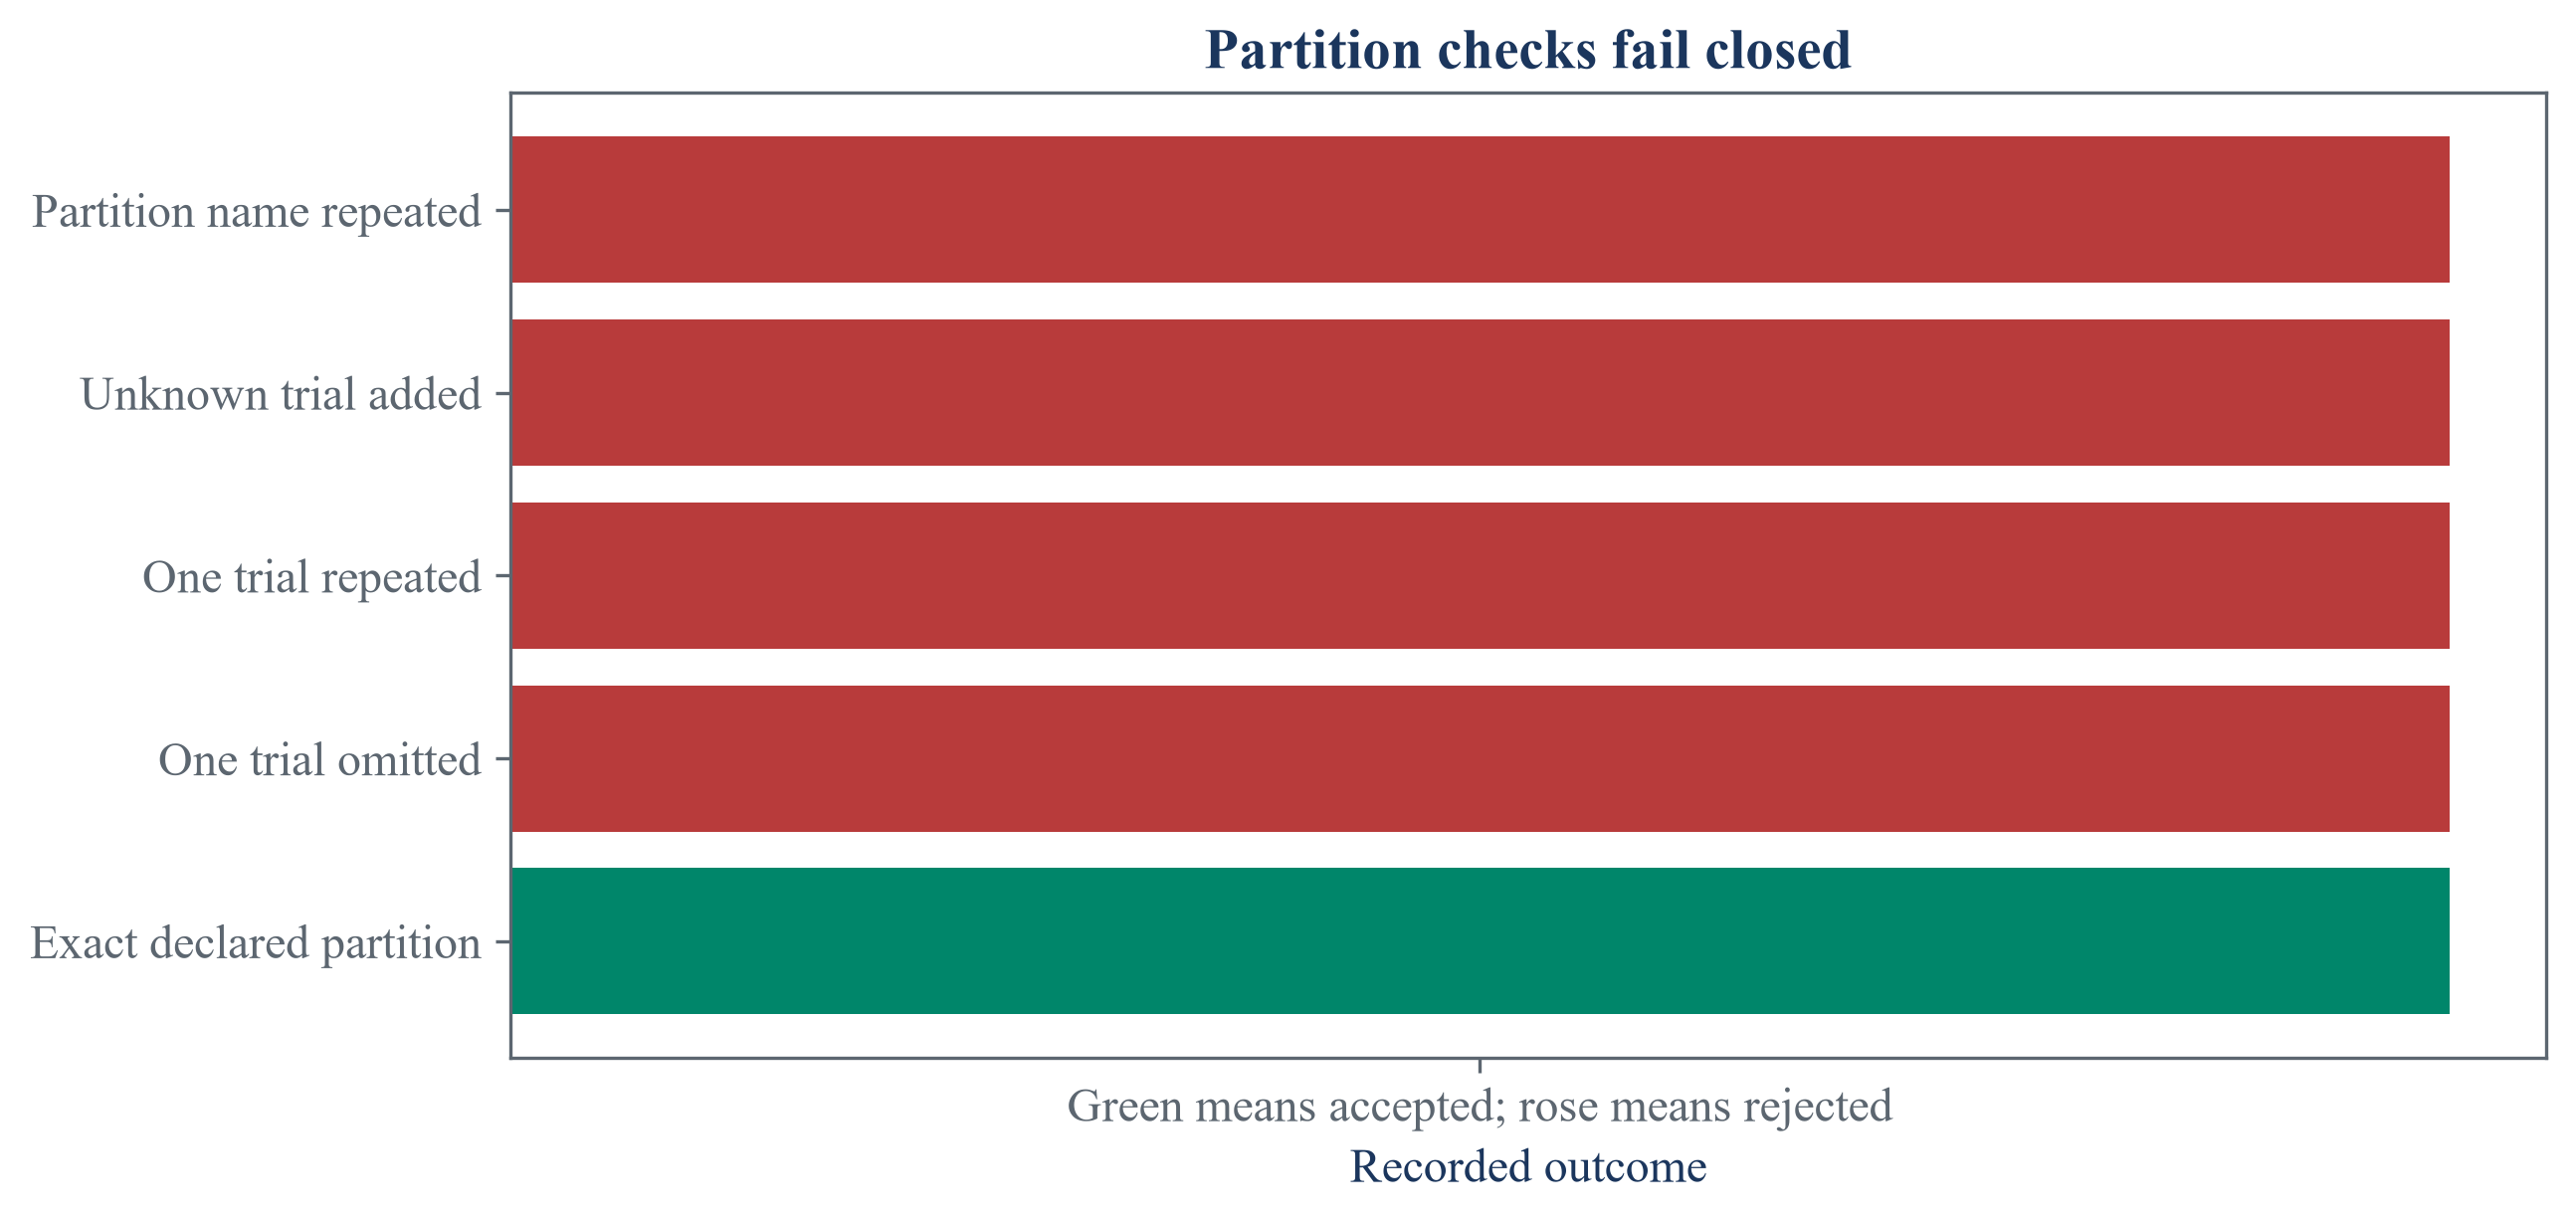

In [2]:
partition_variants = [
    ("Exact declared partition", multiple_testing.family_partitions),
    ("One trial omitted", (("primary", ("strategy-a", "strategy-b")),)),
    ("One trial repeated", (("primary", ("strategy-a", "strategy-b")), ("robustness", ("strategy-b", "strategy-c")))),
    ("Unknown trial added", (("primary", ("strategy-a", "strategy-b")), ("robustness", ("strategy-c", "strategy-d")))),
    ("Partition name repeated", (("primary", ("strategy-a", "strategy-b")), ("primary", ("strategy-c",)))),
]
partition_checks = pd.DataFrame([
    contract_case(name, "Stage 7", lambda partitions=partitions: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, family_partitions=partitions))))
    for name, partitions in partition_variants
])
save_table(partition_checks, "protocol_partition_checks", "Complete partition evidence is accepted and malformed partitions are rejected.", "tab:chapter28-partition-checks")
display(partition_checks)

figure, axis = plt.subplots(figsize=(8.8, 4.2))
colors = [palette["green"] if not value else palette["rose"] for value in partition_checks["Rejected"]]
axis.barh(partition_checks["Case"], np.ones(len(partition_checks)), color=colors)
axis.set_xlim(0.0, 1.05)
axis.set_xlabel("Recorded outcome")
axis.set_xticks([0.5], ["Green means accepted; rose means rejected"])
axis.set_title("Partition checks fail closed")
save_figure(figure, "protocol_partition_checks")

## Public-Return P Values

A long-run variance estimate can allow for serial dependence in a return path:

$$
\widehat{\Omega}
=
\widehat{\gamma}_0+
2\sum_{k=1}^{L}
\left(1-\frac{k}{L+1}\right)\widehat{\gamma}_k.
$$

Here, $\widehat{\Omega}$ is the estimated long-run variance; $\widehat{\gamma}_0$ is the return variance; $\widehat{\gamma}_k$ is the lag-$k$ covariance; $L$ is the chosen lag limit; and the declining factor gives less weight to longer lags.

In [3]:
def dependence_adjusted_p_value(values):
    observations = np.asarray(values, dtype=float)
    centered = observations - observations.mean()
    count = observations.size
    lag_limit = max(1, int(np.floor(4.0 * (count / 100.0) ** (2.0 / 9.0))))
    covariances = [float(np.dot(centered[lag:], centered[:-lag]) / count) for lag in range(1, lag_limit + 1)]
    long_run_variance = float(np.dot(centered, centered) / count)
    long_run_variance += 2.0 * sum((1.0 - lag / (lag_limit + 1.0)) * covariance for lag, covariance in enumerate(covariances, 1))
    standard_error = math.sqrt(max(long_run_variance, np.finfo(float).tiny) / count)
    statistic = observations.mean() / standard_error
    return 2.0 * norm.sf(abs(statistic)), statistic, lag_limit, long_run_variance

trial_returns = public_trial_returns()
p_value_rows = []
for column in trial_returns.columns:
    p_value, statistic, lag_limit, long_run_variance = dependence_adjusted_p_value(trial_returns[column])
    p_value_rows.append({"Declared trial": column, "Observations": len(trial_returns), "Mean daily return": trial_returns[column].mean(), "Dependence-adjusted statistic": statistic, "Raw p value": p_value, "Lag limit": lag_limit, "Long-run variance": long_run_variance})
p_value_table = pd.DataFrame(p_value_rows)
save_table(p_value_table, "protocol_public_p_values", "Dependence-adjusted evidence from the three declared public-return paths.", "tab:chapter28-public-p-values")
display(p_value_table)

,Declared trial,Observations,Mean daily return,Dependence-adjusted statistic,Raw p value,Lag limit,Long-run variance
0,Strategy A,752,0.000338,1.245832,0.212826,6,0.000055
1,Strategy B,752,-0.000152,-0.580084,0.561858,6,0.000052
2,Strategy C,752,0.000152,0.580084,0.561858,6,0.000052


## Comparing two multiple-testing corrections

Holm's adjusted value for the $i$th ordered raw value is:

$$
\widetilde p_{(i)}^{\mathrm H}
=
\max_{1\le j\le i}
\min\!\left\{1,(m-j+1)p_{(j)}\right\}.
$$

Here, $p_{(j)}$ is the $j$th smallest raw p value; $m$ is the number of declared trials; $i$ is an ordered position; and $\widetilde p_{(i)}^{\mathrm H}$ is the Holm-adjusted value after enforcing a nondecreasing sequence.

The Benjamini-Hochberg adjusted value works backward through the ordered raw values:

$$
\widetilde p_{(i)}^{\mathrm{BH}}
=
\min_{i\le j\le m}
\min\!\left\{1,\frac{m}{j}p_{(j)}\right\}.
$$

Here, $p_{(j)}$ is the $j$th smallest raw p value; $m$ is the number of declared trials; $j$ is an ordered position at or above $i$; and $\widetilde p_{(i)}^{\mathrm{BH}}$ is the Benjamini-Hochberg adjusted value after enforcing a nondecreasing sequence.

,Declared trial,Raw p value,Holm adjusted p value,Benjamini-Hochberg adjusted p value,Holm rejects at five percent,Benjamini-Hochberg rejects at five percent
0,Strategy A,0.212826,0.638478,0.561858,False,False
1,Strategy B,0.561858,1,0.561858,False,False
2,Strategy C,0.561858,1,0.561858,False,False


,Method,Role in this notebook,Error target
0,Holm,Calculated for the public-return family,Probability of at least one false rejection
1,Benjamini-Hochberg,Calculated for comparison,Expected false share among rejections
2,Hochberg,Listed as a Stage 7 choice; no separate calcul...,Probability of at least one false rejection
3,Deflated Sharpe ratio,Calculated from declared selection inputs,Selection bias in the reported Sharpe ratio


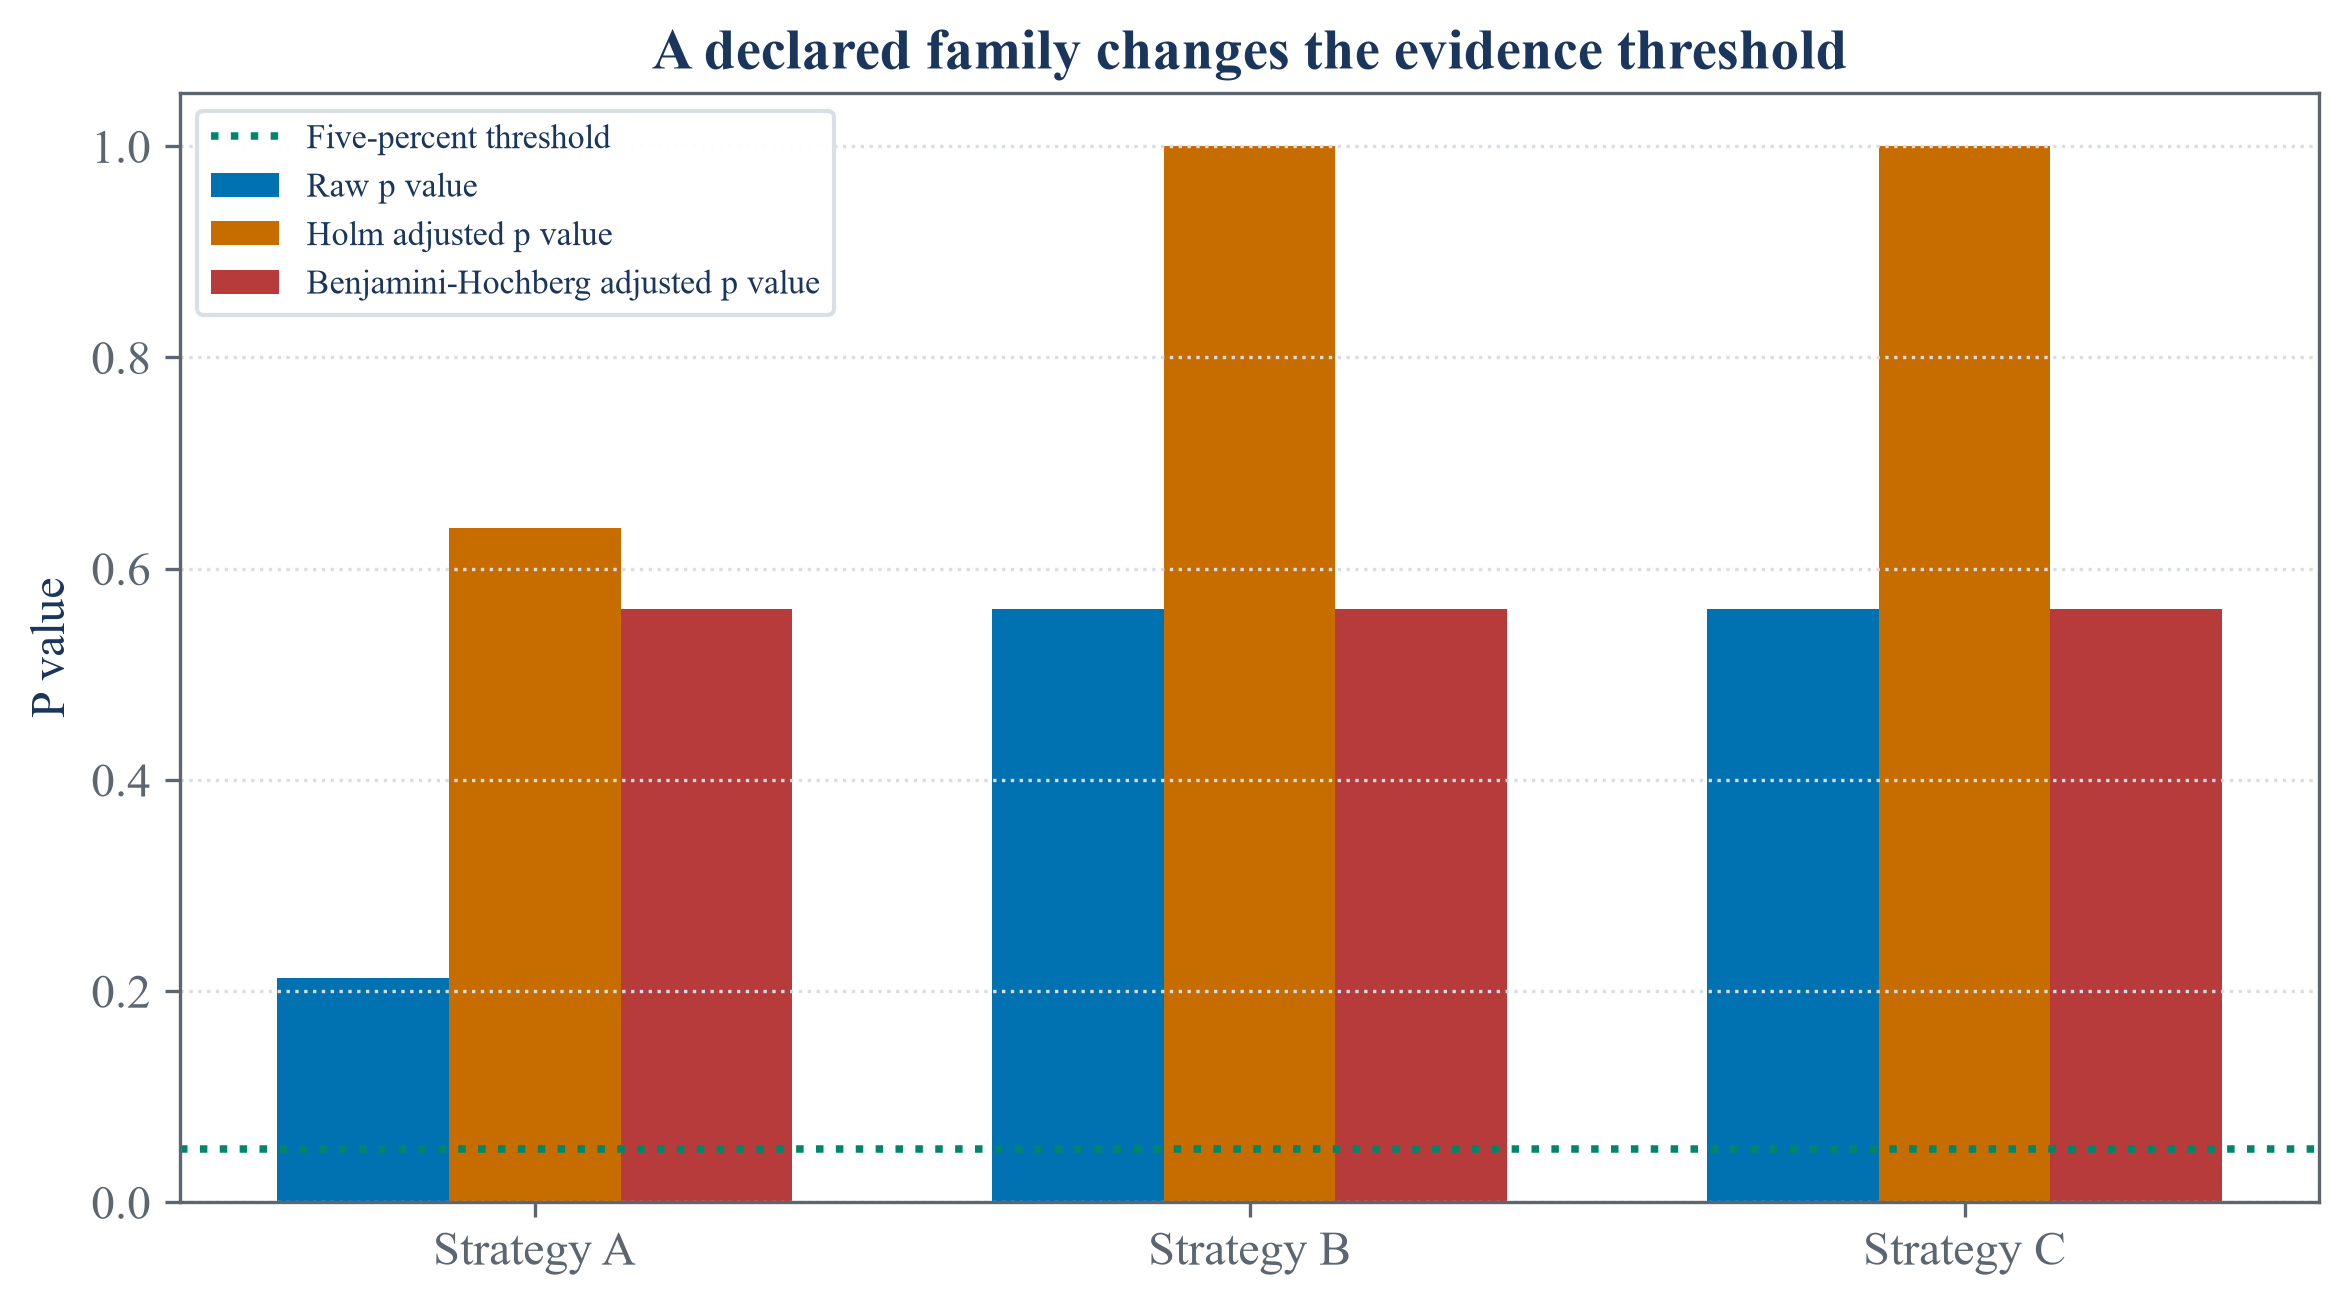

In [4]:
def holm_adjusted(values):
    raw = np.asarray(values, dtype=float)
    order = np.argsort(raw)
    ordered = raw[order]
    adjusted_ordered = np.maximum.accumulate(np.minimum(1.0, (len(raw) - np.arange(len(raw))) * ordered))
    adjusted = np.empty_like(adjusted_ordered)
    adjusted[order] = adjusted_ordered
    return adjusted

def benjamini_hochberg_adjusted(values):
    raw = np.asarray(values, dtype=float)
    order = np.argsort(raw)
    ordered = raw[order]
    candidates = np.minimum(1.0, len(raw) * ordered / np.arange(1, len(raw) + 1))
    adjusted_ordered = np.minimum.accumulate(candidates[::-1])[::-1]
    adjusted = np.empty_like(adjusted_ordered)
    adjusted[order] = adjusted_ordered
    return adjusted

raw_p_values = p_value_table["Raw p value"].to_numpy()
adjustment_table = p_value_table[["Declared trial", "Raw p value"]].copy()
adjustment_table["Holm adjusted p value"] = holm_adjusted(raw_p_values)
adjustment_table["Benjamini-Hochberg adjusted p value"] = benjamini_hochberg_adjusted(raw_p_values)
adjustment_table["Holm rejects at five percent"] = adjustment_table["Holm adjusted p value"] <= multiple_testing.alpha
adjustment_table["Benjamini-Hochberg rejects at five percent"] = adjustment_table["Benjamini-Hochberg adjusted p value"] <= multiple_testing.alpha
save_table(adjustment_table, "protocol_public_adjustments", "Raw and adjusted values for the declared public-return trial family.", "tab:chapter28-public-adjustments")
display(adjustment_table)

method_scope = pd.DataFrame([
    {"Method": "Holm", "Role in this notebook": "Calculated for the public-return family", "Error target": "Probability of at least one false rejection"},
    {"Method": "Benjamini-Hochberg", "Role in this notebook": "Calculated for comparison", "Error target": "Expected false share among rejections"},
    {"Method": "Hochberg", "Role in this notebook": "Listed as a Stage 7 choice; no separate calculation here", "Error target": "Probability of at least one false rejection"},
    {"Method": "Deflated Sharpe ratio", "Role in this notebook": "Calculated from declared selection inputs", "Error target": "Selection bias in the reported Sharpe ratio"},
])
save_table(method_scope, "protocol_adjustment_scope", "The distinct roles of the Stage 7 choices used or listed here.", "tab:chapter28-adjustment-scope")
display(method_scope)

plot_frame = adjustment_table.set_index("Declared trial")[["Raw p value", "Holm adjusted p value", "Benjamini-Hochberg adjusted p value"]]
figure, axis = plt.subplots(figsize=(9.2, 4.8))
positions = np.arange(len(plot_frame))
width = 0.24
for offset, (column, color) in zip([-width, 0.0, width], [(plot_frame.columns[0], palette["cyan"]), (plot_frame.columns[1], palette["amber"]), (plot_frame.columns[2], palette["rose"])]):
    axis.bar(positions + offset, plot_frame[column], width=width, color=color, label=column)
axis.axhline(multiple_testing.alpha, color=palette["green"], linestyle=":", linewidth=1.8, label="Five-percent threshold")
axis.set_xticks(positions, plot_frame.index)
axis.set_ylabel("P value")
axis.set_title("A declared family changes the evidence threshold")
axis.legend(fontsize=8.2)
axis.grid(True, axis="y")
save_figure(figure, "protocol_public_adjustments")

## Deflated Sharpe Evidence

A trial-count benchmark for the largest Sharpe ratio can be approximated by:

$$
\widehat{SR}^{\,*}
=
\sqrt{\widehat V_{SR}}
\left[
(1-\gamma)\Phi^{-1}\!\left(1-\frac{1}{N_{\mathrm{eff}}}\right)
+
\gamma\Phi^{-1}\!\left(1-\frac{1}{eN_{\mathrm{eff}}}\right)
\right].
$$

Here, $\widehat{SR}^{\,*}$ is the selection benchmark; $\widehat V_{SR}$ is the declared variance across Sharpe estimates; $\gamma$ is the Euler constant; $\Phi^{-1}$ is the standard-normal quantile; $N_{\mathrm{eff}}$ is the effective number of trials; and $e$ is the base of the natural logarithm.

The probability that an observed Sharpe ratio exceeds that benchmark is:

$$
\operatorname{PSR}(\widehat{SR}^{\,*})
=
\Phi\!\left(
\frac{(\widehat{SR}-\widehat{SR}^{\,*})\sqrt{T-1}}
{\sqrt{1-\widehat\gamma_3\widehat{SR}+\frac{\widehat\gamma_4-1}{4}\widehat{SR}^{\,2}}}
\right).
$$

Here, $\operatorname{PSR}$ is the probabilistic Sharpe value; $\widehat{SR}$ is the observed Sharpe ratio; $\widehat{SR}^{\,*}$ is the selection benchmark; $T$ is the sample length; $\widehat\gamma_3$ is sample skewness; $\widehat\gamma_4$ is sample Pearson kurtosis; and $\Phi$ is the standard-normal cumulative distribution function.

,Input,Value,Role
0,Variance across Sharpe estimates,0.04,Scale of the selection benchmark
1,Effective trials,2,Independent-equivalent search count
2,Total declared trials,3,Upper bound for effective trials
3,Sample length,252,Precision of the observed Sharpe ratio
4,Skewness,0.1,Asymmetry adjustment
5,Pearson kurtosis,3.2,Tail-shape adjustment


,Effective trials,Selection benchmark,Probability above benchmark,Record accepted
0,1.01,-0.156947,1,True
1,1.25,-0.008727,0.994099,True
2,1.5,0.043178,0.954925,True
3,2,0.103951,0.767461,True
4,2.5,0.142491,0.547413,True
5,2.99,0.170069,0.375102,True


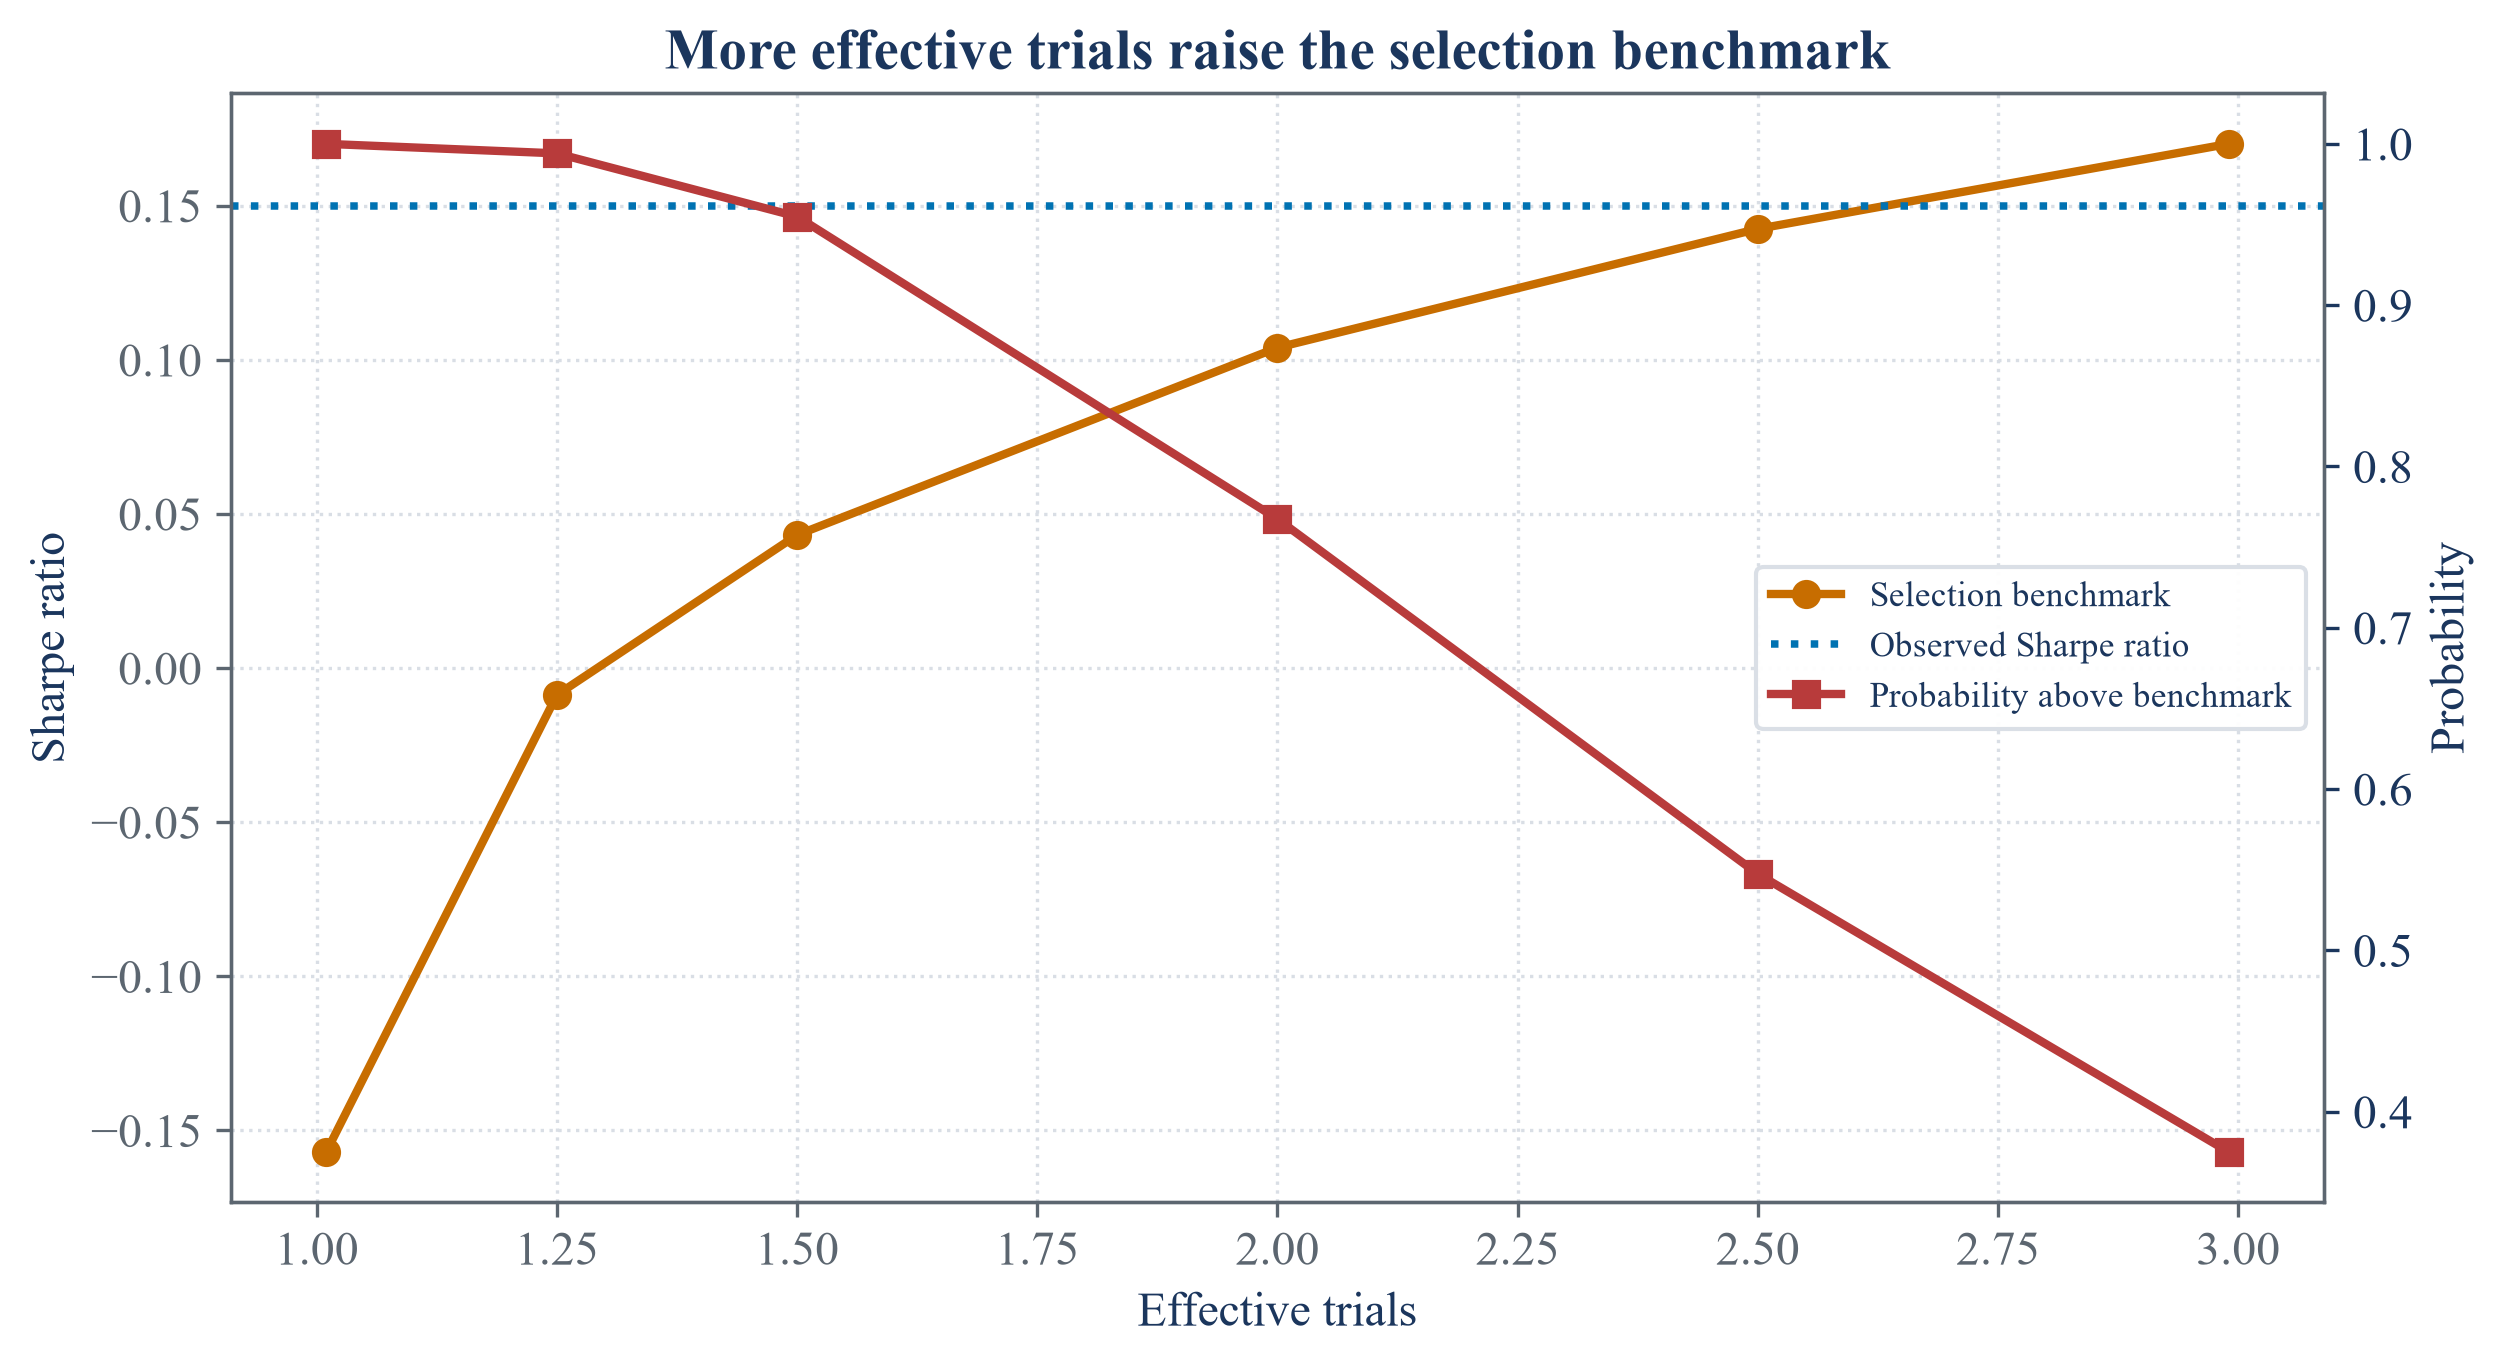

In [5]:
def expected_maximum_sharpe(sharpe_variance, effective_trials):
    euler_constant = 0.5772156649015329
    first_probability = np.clip(1.0 - 1.0 / effective_trials, np.finfo(float).eps, 1.0 - np.finfo(float).eps)
    second_probability = np.clip(1.0 - 1.0 / (math.e * effective_trials), np.finfo(float).eps, 1.0 - np.finfo(float).eps)
    return math.sqrt(sharpe_variance) * ((1.0 - euler_constant) * norm.ppf(first_probability) + euler_constant * norm.ppf(second_probability))

def probabilistic_sharpe(observed_sharpe, benchmark_sharpe, sample_length, skewness, kurtosis):
    denominator = math.sqrt(1.0 - skewness * observed_sharpe + ((kurtosis - 1.0) / 4.0) * observed_sharpe ** 2)
    statistic = (observed_sharpe - benchmark_sharpe) * math.sqrt(sample_length - 1.0) / denominator
    return norm.cdf(statistic)

dsr_inputs = pd.DataFrame([
    {"Input": "Variance across Sharpe estimates", "Value": multiple_testing.sharpe_variance, "Role": "Scale of the selection benchmark"},
    {"Input": "Effective trials", "Value": multiple_testing.effective_trials, "Role": "Independent-equivalent search count"},
    {"Input": "Total declared trials", "Value": len(multiple_testing.declared_trial_ids), "Role": "Upper bound for effective trials"},
    {"Input": "Sample length", "Value": multiple_testing.sample_length, "Role": "Precision of the observed Sharpe ratio"},
    {"Input": "Skewness", "Value": multiple_testing.skewness, "Role": "Asymmetry adjustment"},
    {"Input": "Pearson kurtosis", "Value": multiple_testing.kurtosis, "Role": "Tail-shape adjustment"},
])
save_table(dsr_inputs, "protocol_dsr_inputs", "Declared inputs required for the deflated Sharpe calculation.", "tab:chapter28-dsr-inputs")
display(dsr_inputs)

observed_sharpe = 0.15
effective_grid = np.array([1.01, 1.25, 1.5, 2.0, 2.5, 2.99])
sensitivity_rows = []
for effective_trials in effective_grid:
    benchmark = expected_maximum_sharpe(float(multiple_testing.sharpe_variance), effective_trials)
    probability = probabilistic_sharpe(observed_sharpe, benchmark, int(multiple_testing.sample_length), float(multiple_testing.skewness), float(multiple_testing.kurtosis))
    accepted_report = validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, effective_trials=float(effective_trials))))
    sensitivity_rows.append({"Effective trials": effective_trials, "Selection benchmark": benchmark, "Probability above benchmark": probability, "Record accepted": isinstance(accepted_report, CausalFactorProtocolReport)})
dsr_sensitivity = pd.DataFrame(sensitivity_rows)
save_table(dsr_sensitivity, "protocol_dsr_sensitivity", "Sensitivity of the selection benchmark to the effective trial count.", "tab:chapter28-dsr-sensitivity")
display(dsr_sensitivity)

figure, first_axis = plt.subplots(figsize=(9.0, 4.8))
first_axis.plot(dsr_sensitivity["Effective trials"], dsr_sensitivity["Selection benchmark"], marker="o", color=palette["amber"], linewidth=2.0, label="Selection benchmark")
first_axis.axhline(observed_sharpe, color=palette["cyan"], linestyle=":", linewidth=1.8, label="Observed Sharpe ratio")
first_axis.set_xlabel("Effective trials")
first_axis.set_ylabel("Sharpe ratio")
second_axis = first_axis.twinx()
second_axis.plot(dsr_sensitivity["Effective trials"], dsr_sensitivity["Probability above benchmark"], marker="s", color=palette["rose"], linewidth=2.0, label="Probability above benchmark")
second_axis.set_ylabel("Probability")
second_axis.tick_params(colors=palette["text"])
first_axis.set_title("More effective trials raise the selection benchmark")
first_axis.grid(True)
handles_a, labels_a = first_axis.get_legend_handles_labels()
handles_b, labels_b = second_axis.get_legend_handles_labels()
first_axis.legend(handles_a + handles_b, labels_a + labels_b, fontsize=8.5, loc="center right")
save_figure(figure, "protocol_dsr_sensitivity")

## Feasible Moment Records

Skewness and Pearson kurtosis must satisfy the moment inequality:

$$
\widehat\gamma_3^{\,2}\le \widehat\gamma_4-1.
$$

Here, $\widehat\gamma_3$ is the declared skewness and $\widehat\gamma_4$ is the declared Pearson kurtosis; the inequality rules out pairs of moments that no probability distribution can have.

,Skewness,Pearson kurtosis,Moment inequality holds,Record accepted
0,-1.5,1,False,False
1,-1,1,False,False
2,-0.5,1,False,False
3,0,1,True,True
4,0.5,1,False,False
5,1,1,False,False
6,1.5,1,False,False
7,-1.5,1.5,False,False
8,-1,1.5,False,False
9,-0.5,1.5,True,True


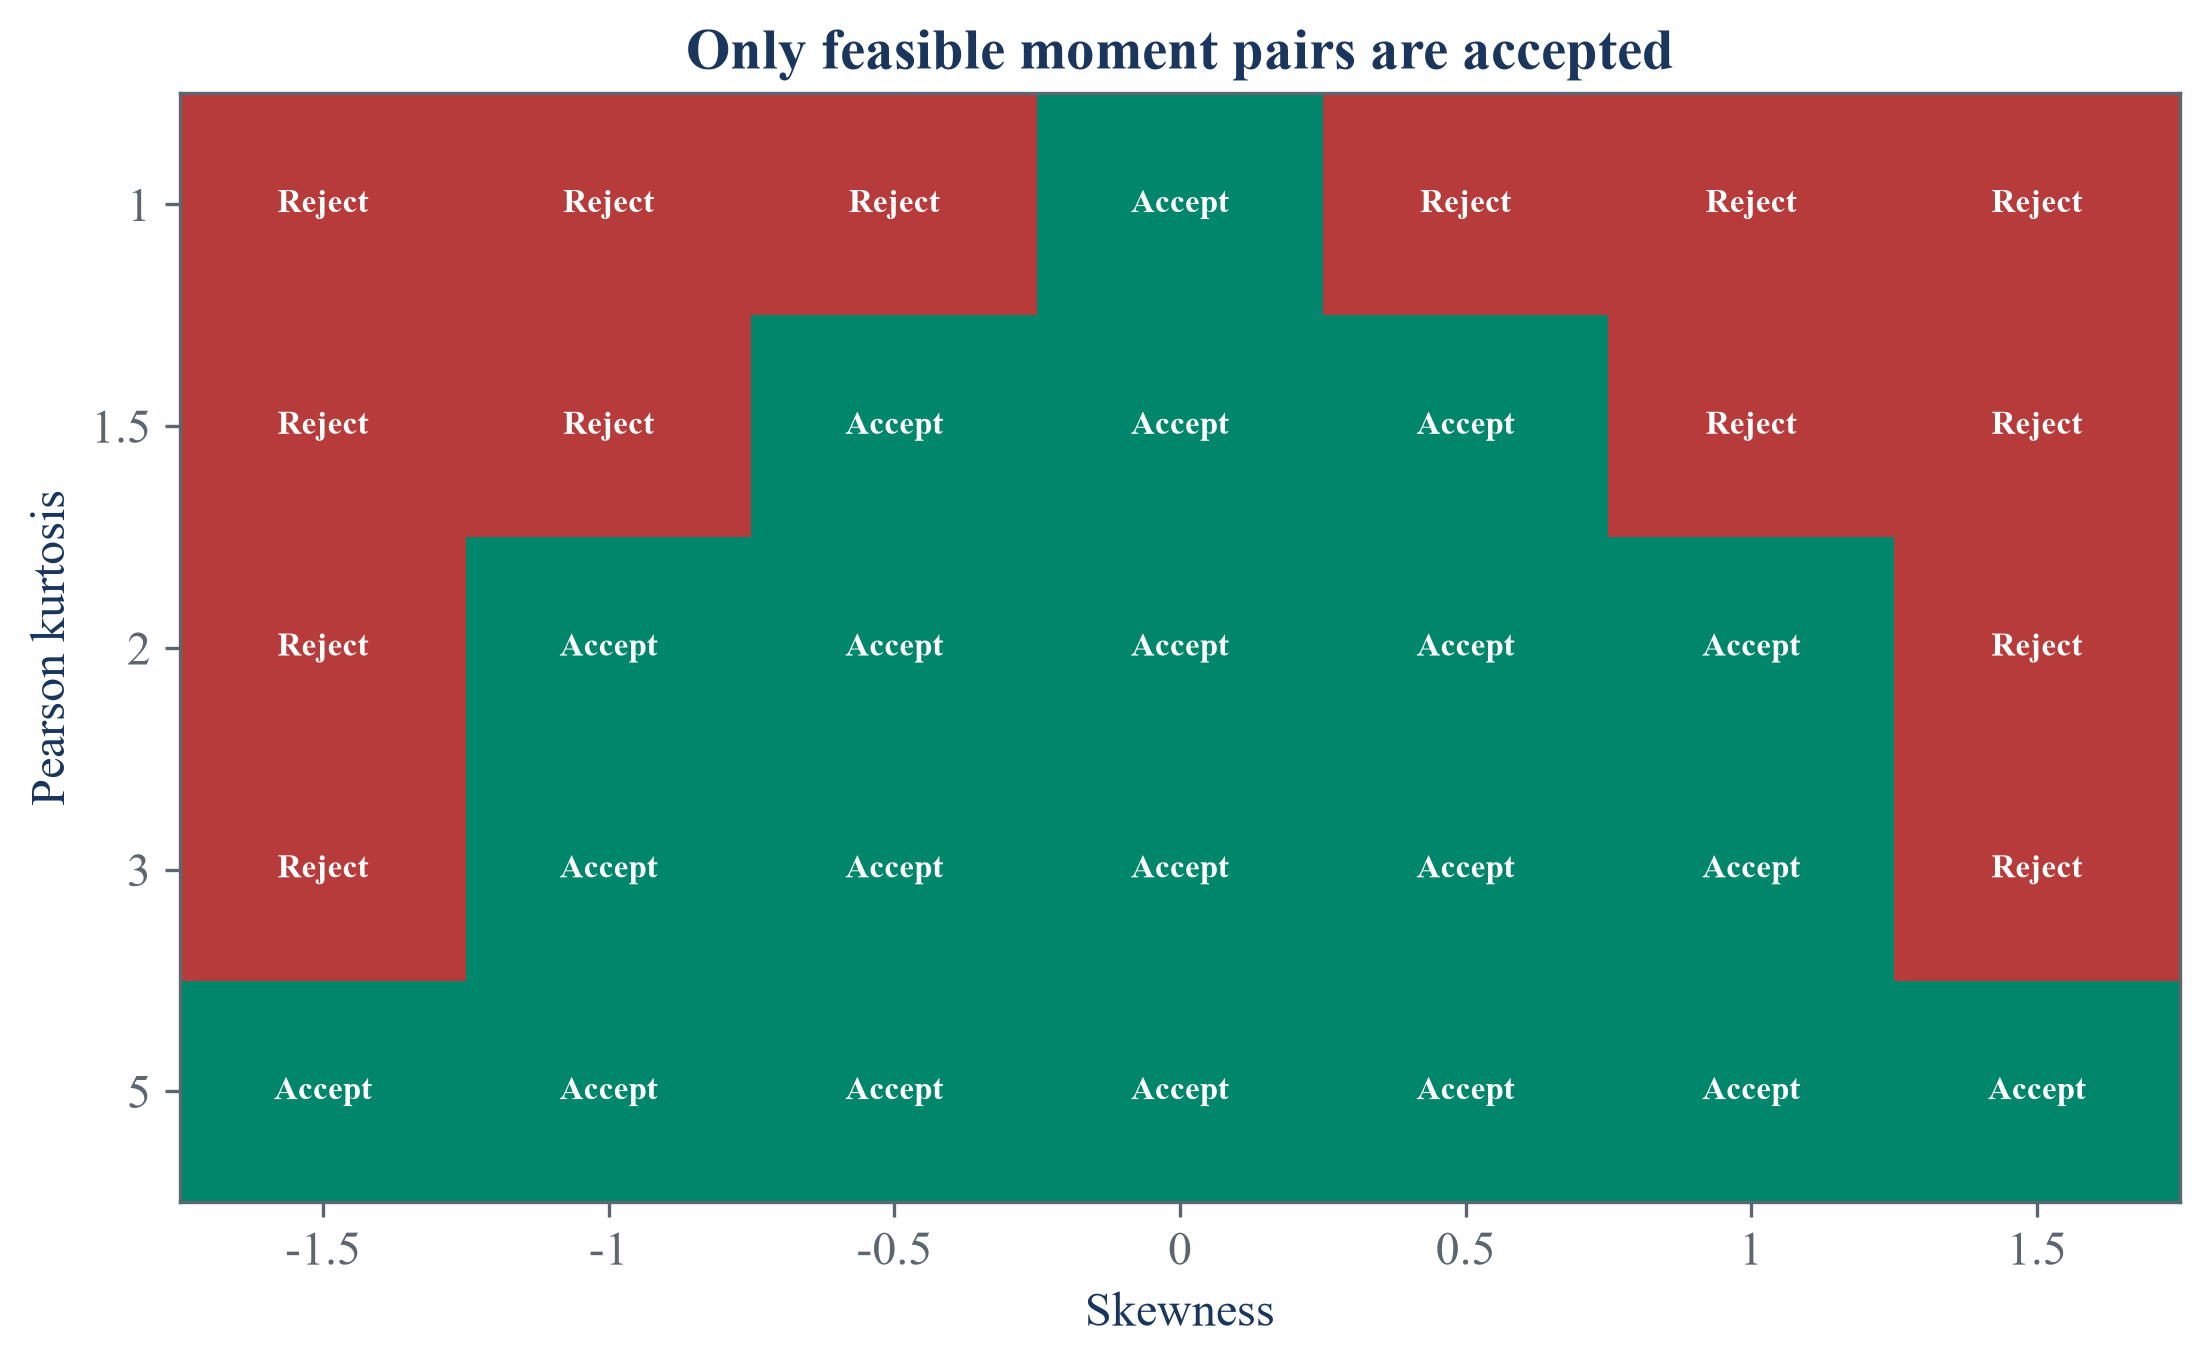

In [6]:
skewness_values = np.array([-1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5])
kurtosis_values = np.array([1.0, 1.5, 2.0, 3.0, 5.0])
moment_acceptance = np.zeros((len(kurtosis_values), len(skewness_values)), dtype=int)
moment_rows = []
for row, kurtosis in enumerate(kurtosis_values):
    for column, skewness in enumerate(skewness_values):
        result = contract_case("Moment pair", "Stage 7", lambda skewness=skewness, kurtosis=kurtosis: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, skewness=float(skewness), kurtosis=float(kurtosis)))))
        moment_acceptance[row, column] = int(not result["Rejected"])
        moment_rows.append({"Skewness": skewness, "Pearson kurtosis": kurtosis, "Moment inequality holds": skewness ** 2 <= kurtosis - 1.0 + 1e-12, "Record accepted": not result["Rejected"]})
moment_table = pd.DataFrame(moment_rows)
save_table(moment_table, "protocol_moment_grid", "Feasible and infeasible skewness-kurtosis pairs.", "tab:chapter28-moment-grid")
display(moment_table)

figure, axis = plt.subplots(figsize=(8.6, 4.8))
axis.imshow(moment_acceptance, cmap=matplotlib.colors.ListedColormap([palette["rose"], palette["green"]]), vmin=0, vmax=1, aspect="auto")
for row in range(moment_acceptance.shape[0]):
    for column in range(moment_acceptance.shape[1]):
        axis.text(column, row, "Accept" if moment_acceptance[row, column] else "Reject", ha="center", va="center", color=palette["background"], fontsize=8.0, fontweight="bold")
axis.set_xticks(range(len(skewness_values)), [display_float(value) for value in skewness_values])
axis.set_yticks(range(len(kurtosis_values)), [display_float(value) for value in kurtosis_values])
axis.set_xlabel("Skewness")
axis.set_ylabel("Pearson kurtosis")
axis.set_title("Only feasible moment pairs are accepted")
save_figure(figure, "protocol_moment_grid")

## Dependence Evidence

The correlation matrix records dependence among the declared public-return paths:

$$
\widehat\rho_{ij}
=
\frac{\sum_{t=1}^{T}(R_{it}-\overline R_i)(R_{jt}-\overline R_j)}
{\sqrt{\sum_{t=1}^{T}(R_{it}-\overline R_i)^2}\sqrt{\sum_{t=1}^{T}(R_{jt}-\overline R_j)^2}}.
$$

Here, $\widehat\rho_{ij}$ is the sample correlation between trials $i$ and $j$; $R_{it}$ and $R_{jt}$ are their returns at time $t$; $\overline R_i$ and $\overline R_j$ are their sample means; and $T$ is the number of public observations.

,Requirement,Recorded evidence,Complete
0,Dependence flag,Backtests are not independent,True
1,P-value estimator,estimator accounting for time dependence,True
2,Time-dependence treatment,purged temporal folds,True
3,Independence assumption in inputs,Explicitly rejected,True
4,Selection-bias evidence,selection-bias-evidence,True


,Declared trial,Strategy A,Strategy B,Strategy C
0,Strategy A,1,-0.164445,0.164445
1,Strategy B,-0.164445,1,-1
2,Strategy C,0.164445,-1,1


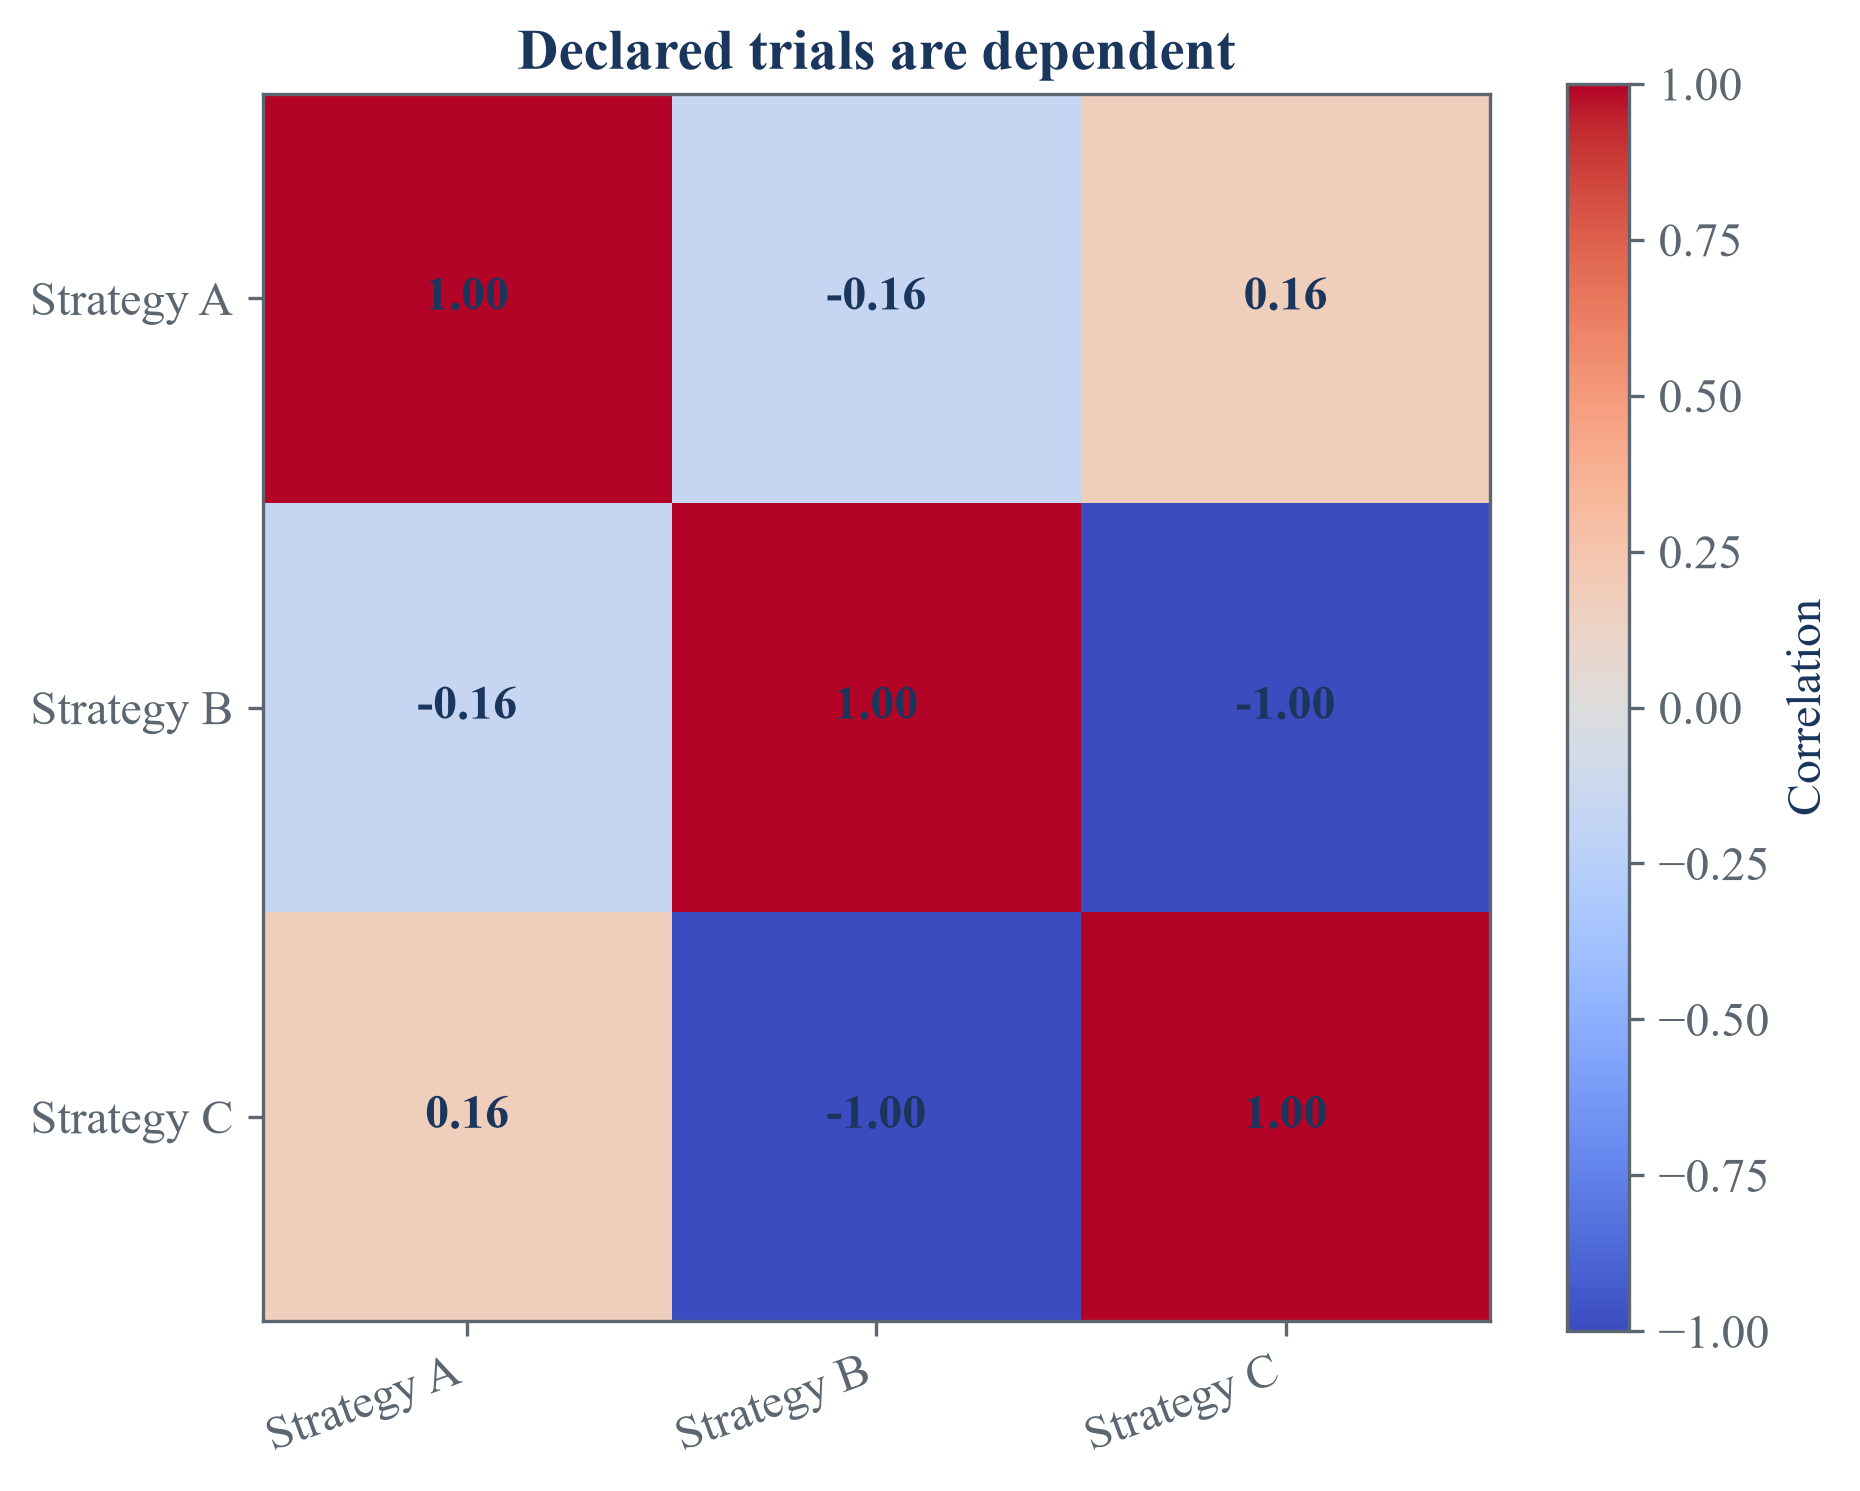

In [7]:
dependence_record = pd.DataFrame([
    {"Requirement": "Dependence flag", "Recorded evidence": "Backtests are not independent", "Complete": not multiple_testing.backtests_independent},
    {"Requirement": "P-value estimator", "Recorded evidence": multiple_testing.p_value_estimator, "Complete": bool(multiple_testing.p_value_estimator)},
    {"Requirement": "Time-dependence treatment", "Recorded evidence": multiple_testing.time_dependence_model, "Complete": bool(multiple_testing.time_dependence_model)},
    {"Requirement": "Independence assumption in inputs", "Recorded evidence": "Explicitly rejected", "Complete": multiple_testing.p_value_inputs_assume_independence is False},
    {"Requirement": "Selection-bias evidence", "Recorded evidence": multiple_testing.selection_bias_evidence_id, "Complete": bool(multiple_testing.selection_bias_evidence_id)},
])
save_table(dependence_record, "protocol_dependence_record", "Evidence required when trials and return observations are dependent.", "tab:chapter28-dependence-record")
display(dependence_record)

correlation = trial_returns.corr()
correlation_table = correlation.reset_index().rename(columns={"index": "Declared trial"})
save_table(correlation_table, "protocol_trial_correlation", "Correlation among the three declared public-return paths.", "tab:chapter28-trial-correlation")
display(correlation_table)

figure, axis = plt.subplots(figsize=(6.6, 5.4))
image = axis.imshow(correlation.to_numpy(), cmap="coolwarm", vmin=-1.0, vmax=1.0)
for row in range(len(correlation)):
    for column in range(len(correlation)):
        axis.text(column, row, f"{correlation.iloc[row, column]:.2f}", ha="center", va="center", color=palette["text"], fontweight="bold")
axis.set_xticks(range(len(correlation)), correlation.columns, rotation=20, ha="right")
axis.set_yticks(range(len(correlation)), correlation.index)
axis.set_title("Declared trials are dependent")
figure.colorbar(image, ax=axis, label="Correlation")
save_figure(figure, "protocol_trial_correlation")

## Checking released results against immutable records

In [8]:
records = [
    report.variable_selection,
    report.causal_discovery,
    report.causal_adjustment_set,
    report.causal_explanatory_and_predictive_power,
    report.causal_portfolio_construction,
    report.backtest,
    report.multiple_testing_adjustments,
    report,
]
record_rows = []
for value in records:
    first_field = fields(value)[0].name
    try:
        setattr(value, first_field, getattr(value, first_field))
        frozen = False
    except FrozenInstanceError:
        frozen = True
    tuple_fields = [getattr(value, field.name) for field in fields(value) if isinstance(getattr(value, field.name), tuple)]
    record_rows.append({"Evidence record": re.sub(r"(?<!^)(?=[A-Z])", " ", type(value).__name__).replace(" Stage", "").strip(), "Frozen": frozen, "Tuple fields": len(tuple_fields), "Passed": frozen and len(tuple_fields) > 0})
record_table = pd.DataFrame(record_rows)
save_table(record_table, "protocol_record_checks", "Immutability checks for the seven stage records and complete report.", "tab:chapter28-record-checks")
display(record_table)

public_names = [
    EventHorizon,
    FoldEvidence,
    ValidationEvidence,
    VariableSelectionStage,
    CausalDiscoveryStage,
    CausalAdjustmentSetStage,
    CausalExplanatoryAndPredictivePowerStage,
    CausalPortfolioConstructionStage,
    BacktestStage,
    MultipleTestingAdjustmentsStage,
    CausalFactorProtocolReport,
    validate_causal_factor_protocol,
]
public_name_table = pd.DataFrame([{"Released name": value.__name__, "Kind": "Check" if inspect.isfunction(value) else "Evidence record", "Covered here": "Yes"} for value in public_names])
public_name_table["Released name"] = public_name_table["Released name"].map(lambda value: re.sub(r"(?<!^)(?=[A-Z])", " ", value).replace("_", " ").strip())
save_table(public_name_table, "protocol_public_names", "All twelve released protocol names covered by the chapter notebooks.", "tab:chapter28-public-names")
display(public_name_table)

,Evidence record,Frozen,Tuple fields,Passed
0,Variable Selection,True,2,True
1,Causal Discovery,True,5,True
2,Causal Adjustment Set,True,9,True
3,Causal Explanatory And Predictive Power,True,3,True
4,Causal Portfolio Construction,True,4,True
5,Backtest,True,2,True
6,Multiple Testing Adjustments,True,3,True
7,Causal Factor Protocol Report,True,1,True


,Released name,Kind,Covered here
0,Event Horizon,Evidence record,Yes
1,Fold Evidence,Evidence record,Yes
2,Validation Evidence,Evidence record,Yes
3,Variable Selection Stage,Evidence record,Yes
4,Causal Discovery Stage,Evidence record,Yes
5,Causal Adjustment Set Stage,Evidence record,Yes
6,Causal Explanatory And Predictive Power Stage,Evidence record,Yes
7,Causal Portfolio Construction Stage,Evidence record,Yes
8,Backtest Stage,Evidence record,Yes
9,Multiple Testing Adjustments Stage,Evidence record,Yes


## Rejected Stage 7 Evidence

,Case,Stage,Result,Message,Rejected
0,Trial family differs from the report,Stage 7,Rejected,Stage 7: trial-family identifier must match th...,True
1,Declared trials differ from the report,Stage 7,Rejected,Stage 7: declared trials must match the report...,True
2,Partition coverage is incomplete,Stage 7,Rejected,Stage 7: family partitions must cover declared...,True
3,Partitions overlap,Stage 7,Rejected,Stage 7: family partitions must be disjoint,True
4,Significance level equals zero,Stage 7,Rejected,Stage 7: alpha must be a finite number between...,True
5,Significance level equals one,Stage 7,Rejected,Stage 7: alpha must be a finite number between...,True
6,Independence is asserted,Stage 7,Rejected,Stage 7: backtest dependence must be represented,True
7,P-value estimator is missing,Stage 7,Rejected,Stage 7: p-value estimator must be declared,True
8,Time treatment is missing,Stage 7,Rejected,Stage 7: time dependence treatment must be dec...,True
9,P-value inputs assume independence,Stage 7,Rejected,Stage 7: p-value inputs must explicitly reject...,True


,Evidence group,Rejected cases
0,Family identity and coverage,4
1,Decision threshold and dependence,6
2,Deflated Sharpe inputs,4


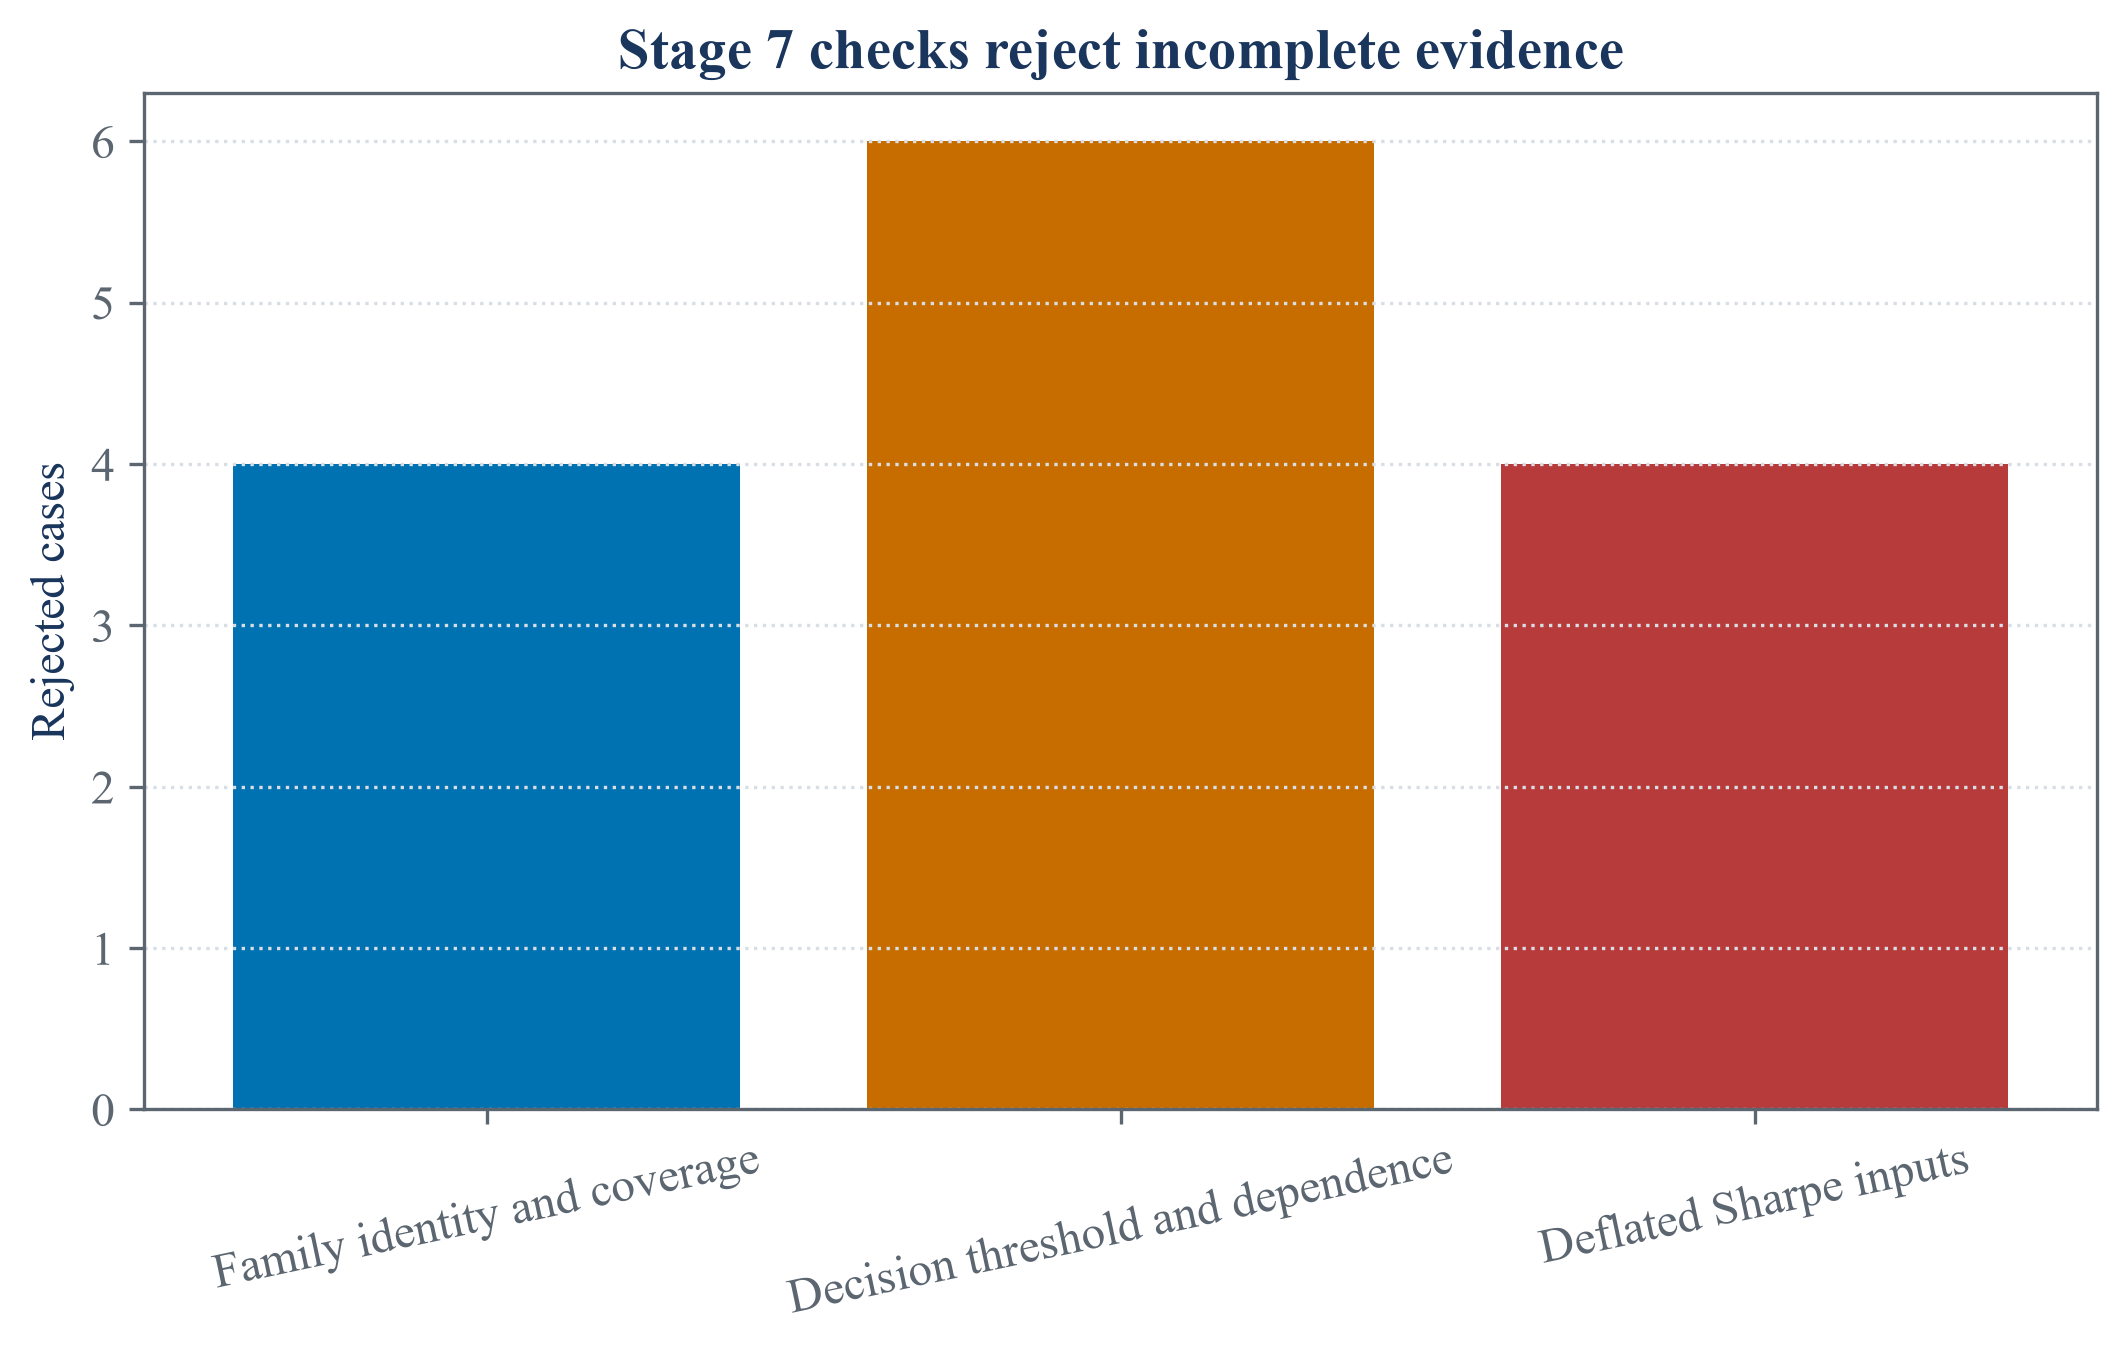

,Question,Evidence
0,Was one complete family declared before correc...,Matching family and trial identifiers in Stage...
1,Do named partitions cover the family once?,Complete and disjoint partition records
2,Does the correction recognize time dependence?,A declared estimator and time-dependence treat...
3,Are selection inputs feasible and complete?,"Trial count, variance, sample length, moments,..."
4,Can a partial record pass?,No; incomplete records are rejected


In [9]:
rejection_cases = [
    ("Trial family differs from the report", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, trial_family_id="different-family")))),
    ("Declared trials differ from the report", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, declared_trial_ids=("strategy-a", "strategy-b"))))),
    ("Partition coverage is incomplete", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, family_partitions=(("primary", ("strategy-a", "strategy-b")),))))),
    ("Partitions overlap", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, family_partitions=(("primary", ("strategy-a", "strategy-b")), ("robustness", ("strategy-b", "strategy-c"))))))),
    ("Significance level equals zero", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, alpha=0.0)))),
    ("Significance level equals one", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, alpha=1.0)))),
    ("Independence is asserted", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, backtests_independent=True)))),
    ("P-value estimator is missing", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, p_value_estimator="")))),
    ("Time treatment is missing", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, time_dependence_model="")))),
    ("P-value inputs assume independence", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, p_value_inputs_assume_independence=True)))),
    ("Effective trials equal total trials", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, effective_trials=3.0)))),
    ("Pearson kurtosis is below one", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, kurtosis=0.5)))),
    ("Moment inequality is violated", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, skewness=2.0, kurtosis=3.0)))),
    ("Selection-bias evidence is missing", lambda: validate_causal_factor_protocol(replace(report, multiple_testing_adjustments=replace(multiple_testing, selection_bias_evidence_id="")))),
]
rejection_table = pd.DataFrame([contract_case(name, "Stage 7", action) for name, action in rejection_cases])
save_table(rejection_table, "protocol_stage7_rejections", "Incomplete or inconsistent Stage 7 records rejected by the released checks.", "tab:chapter28-stage7-rejections")
display(rejection_table)

rejection_groups = pd.DataFrame([
    {"Evidence group": "Family identity and coverage", "Rejected cases": 4},
    {"Evidence group": "Decision threshold and dependence", "Rejected cases": 6},
    {"Evidence group": "Deflated Sharpe inputs", "Rejected cases": 4},
])
save_table(rejection_groups, "protocol_stage7_rejection_groups", "Rejected Stage 7 cases grouped by the missing or inconsistent evidence.", "tab:chapter28-stage7-rejection-groups")
display(rejection_groups)

figure, axis = plt.subplots(figsize=(8.4, 4.4))
axis.bar(rejection_groups["Evidence group"], rejection_groups["Rejected cases"], color=[palette["cyan"], palette["amber"], palette["rose"]])
axis.set_ylabel("Rejected cases")
axis.set_title("Stage 7 checks reject incomplete evidence")
axis.tick_params(axis="x", rotation=12)
axis.grid(True, axis="y")
save_figure(figure, "protocol_stage7_rejections")

section_summary = pd.DataFrame([
    {"Question": "Was one complete family declared before correction?", "Evidence": "Matching family and trial identifiers in Stages 6 and 7"},
    {"Question": "Do named partitions cover the family once?", "Evidence": "Complete and disjoint partition records"},
    {"Question": "Does the correction recognize time dependence?", "Evidence": "A declared estimator and time-dependence treatment"},
    {"Question": "Are selection inputs feasible and complete?", "Evidence": "Trial count, variance, sample length, moments, and selection record"},
    {"Question": "Can a partial record pass?", "Evidence": "No; incomplete records are rejected"},
])
save_table(section_summary, "protocol_section3_summary", "Questions answered by the Stage 7 evidence record.", "tab:chapter28-section3-summary")
display(section_summary)

## Tests

In [10]:
assert report.backtest.trial_family_id == multiple_testing.trial_family_id
assert report.backtest.declared_trial_ids == multiple_testing.declared_trial_ids
assert np.all(partition_matrix.sum(axis=0) == 1)
assert not partition_checks.loc[partition_checks["Case"] == "Exact declared partition", "Rejected"].iloc[0]
assert partition_checks.loc[partition_checks["Case"] != "Exact declared partition", "Rejected"].all()
assert p_value_table["Raw p value"].between(0.0, 1.0).all()
assert adjustment_table[["Holm adjusted p value", "Benjamini-Hochberg adjusted p value"]].apply(lambda values: values.between(0.0, 1.0).all()).all()
assert np.all(adjustment_table["Holm adjusted p value"] + 1e-15 >= adjustment_table["Raw p value"])
assert np.all(adjustment_table["Benjamini-Hochberg adjusted p value"] + 1e-15 >= adjustment_table["Raw p value"])
assert dsr_sensitivity["Record accepted"].all()
assert dsr_sensitivity["Selection benchmark"].is_monotonic_increasing
assert dsr_sensitivity["Probability above benchmark"].is_monotonic_decreasing
assert (moment_table["Moment inequality holds"] == moment_table["Record accepted"]).all()
assert dependence_record["Complete"].all()
assert np.allclose(np.diag(correlation), 1.0)
assert record_table["Passed"].all()
assert len(public_name_table) == 12
assert rejection_table["Rejected"].all()
assert rejection_groups["Rejected cases"].sum() == len(rejection_table)
for stem in ["protocol_partition_membership", "protocol_partition_checks", "protocol_public_adjustments", "protocol_dsr_sensitivity", "protocol_moment_grid", "protocol_trial_correlation", "protocol_stage7_rejections"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["protocol_trial_family_identity", "protocol_family_partitions", "protocol_partition_membership", "protocol_partition_checks", "protocol_public_p_values", "protocol_public_adjustments", "protocol_adjustment_scope", "protocol_dsr_inputs", "protocol_dsr_sensitivity", "protocol_moment_grid", "protocol_dependence_record", "protocol_trial_correlation", "protocol_record_checks", "protocol_public_names", "protocol_stage7_rejections", "protocol_stage7_rejection_groups", "protocol_section3_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()